## Packages

In [1]:
from datetime import datetime, timedelta 
import pandas as pd
import os
from sunpy.net import Fido, attrs as a
from sunpy.timeseries import TimeSeries
from sunpy.timeseries.sources.goes import XRSTimeSeries
import astropy.units as u
from sunkit_instruments.goes_xrs import calculate_temperature_em
import matplotlib.pyplot as plt
import numpy as np
from sunpy.data import manager
import netCDF4 as nc
import os
import pandas as pd
from datetime import datetime, timedelta
import copy
from matplotlib import colormaps
list(colormaps)
#from colorspacious import cspace_converter
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap
from matplotlib import cm
from matplotlib.colors import ListedColormap
import matplotlib.dates as mdates
from matplotlib.ticker import LogFormatter
from matplotlib.ticker import LogFormatterMathtext
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import FuncFormatter
from IPython.display import HTML, display
import matplotlib.pyplot as plt
import seaborn as sns
import re
import glob

/Users/nohoraprieto/miniforge3/envs/sunpy/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Funciones gráficas

In [2]:
def plot_fai_and_flare_lines(df_combined, df_fai_assoc, df_fai_all, df_flare_data, 
                             flare_start_time, flare_end_time, graphics_dir,
                             freq_ticks='10min', ymin=1e-9, ymax=1e-4,
                             figsize=(13, 5), save_plot=True, annotate_counts=False):
    """
    Plots XRS A and B on a logarithmic scale with vertical lines for:
      - All FAI candidates (dark gray)
      - True FAIs (pink)
      - Associated FAIs (red dashed)
      - Flare start, peak, end times (green, blue, orange)
    
    Parameters
    ----------
    df_combined : pd.DataFrame
        Main GOES time series with 'date', 'xrsa', 'xrsb'.
    df_fai_assoc : pd.DataFrame
        FAI dataframe with flags FAI_true and Associated_Flare.
    df_fai_all : pd.DataFrame
        All candidate FAIs (before filtering).
    df_flare_data : pd.DataFrame
        Flare catalog with StartTime, PeakTime, EndTime.
    flare_start_time, flare_end_time : str or datetime
        Interval to plot.
    graphics_dir : str
        Output folder for saved plot.
    freq_ticks : str, optional
        Major tick frequency (e.g., '10min').
    ymin, ymax : float, optional
        Y-axis log scale limits.
    figsize : tuple, optional
        Figure size in inches.
    save_plot : bool, optional
        Whether to save the plot to disk.
    """

    # Convert times
    flare_start_time = pd.to_datetime(flare_start_time)
    flare_end_time = pd.to_datetime(flare_end_time)

    print(f"Buscando datos entre: {flare_start_time} y {flare_end_time}")

    # Ensure datetime columns
    for df, col in [(df_combined, 'date'),
                    (df_fai_assoc, 'date'),
                    (df_fai_all, 'date')]:
        df[col] = pd.to_datetime(df[col])

    for col in ['StartTime', 'PeakTime', 'EndTime']:
        df_flare_data[col] = pd.to_datetime(df_flare_data[col])

    # Filter data within interval
    df_plot = df_combined[(df_combined['date'] >= flare_start_time) & 
                          (df_combined['date'] <= flare_end_time)].copy()
    df_fai_interval = df_fai_assoc[(df_fai_assoc['date'] >= flare_start_time) & 
                                   (df_fai_assoc['date'] <= flare_end_time)].copy()
    df_fai_all_interval = df_fai_all[(df_fai_all['date'] >= flare_start_time) & 
                                     (df_fai_all['date'] <= flare_end_time)].copy()

    # Print basic info
    print(f"Datos en df_plot: {len(df_plot)}, FAI_assoc: {len(df_fai_interval)}, FAI_all: {len(df_fai_all_interval)}")

    if df_plot.empty:
        print("⚠️ No hay datos de GOES en el rango seleccionado.")
        return

    # Configure plot style
    plt.rcParams.update({
        "axes.titlesize": 16, "axes.labelsize": 16,
        "xtick.labelsize": 15, "ytick.labelsize": 15,
        "legend.fontsize": 13
    })

    # Create figure
    fig, ax = plt.subplots(figsize=figsize)
    x_vals = np.arange(len(df_plot))

    # Plot XRS A & B
    ax.plot(x_vals, df_plot['xrsa'], label='XRS A', color='blue', linewidth=1)
    ax.plot(x_vals, df_plot['xrsb'], label='XRS B', color='red', linewidth=1)
    ax.set_yscale('log')
    ax.set_ylim(ymin, ymax)
    ax.set_ylabel('X-ray Flux [W/m²]')
    ax.set_xlabel(f"Time [UTC] – {flare_start_time:%d %b %Y}")
    ax.set_title(f'XRS A and B with FAI and Flare Times\n{flare_start_time:%Y-%m-%d %H:%M} to {flare_end_time:%H:%M}')
    ax.grid(True, alpha=0.3)

    # ---------- Configure X ticks ----------
    major_times = pd.date_range(start=flare_start_time.ceil('10min'),
                                end=flare_end_time, freq=freq_ticks)
    major_indices = np.searchsorted(df_plot['date'].values, major_times.values)
    major_labels = [t.strftime('%H:%M') for t in major_times]
    minor_times = pd.date_range(start=flare_start_time.ceil('1min'),
                                end=flare_end_time, freq='1min')
    minor_indices = np.searchsorted(df_plot['date'].values, minor_times.values)

    ax.set_xticks(major_indices)
    ax.set_xticklabels(major_labels)
    ax.set_xticks(minor_indices, minor=True)

    # ---------- Plot all FAI candidates (dark gray) ----------
    for i, fai_time in enumerate(df_fai_all_interval['date']):
        idx = np.searchsorted(df_plot['date'].values, np.datetime64(fai_time))
        ax.axvline(x=idx, color='dimgray', linestyle='-', linewidth=1.5, alpha=0.7,
                   label='FAI Candidate' if i == 0 else "")

    # ---------- Plot FAI_true (pink) ----------
    fai_true_times = df_fai_interval.loc[df_fai_interval['FAI_true'] == True, 'date']
    for i, fai_time in enumerate(fai_true_times):
        idx = np.searchsorted(df_plot['date'].values, np.datetime64(fai_time))
        ax.axvline(x=idx, color='#FF69B4', linestyle='-', linewidth=1.5, alpha=0.7,
                   label='FAI Alert' if i == 0 else "")

    # ---------- Plot Associated_Flare (red dashed) ----------
    associated_times = df_fai_interval.loc[df_fai_interval['Associated_Flare'] == True, 'date']
    for i, assoc_time in enumerate(associated_times):
        idx = np.searchsorted(df_plot['date'].values, np.datetime64(assoc_time))
        # Guiones de 10 puntos con espacio de 5 puntos
        ax.axvline(x=idx, color='red', linestyle=(0, (6, 6)), linewidth=1.5, alpha=0.7,
        #ax.axvline(x=idx, color='red', linestyle='--', linewidth=1.5, alpha=0.7,
                   label='Associated Flare' if i == 0 else "")

    # ---------- Flare information ----------
    flares_in_interval = df_flare_data[
        (df_flare_data['PeakTime'] >= flare_start_time) & 
        (df_flare_data['PeakTime'] <= flare_end_time)
    ]
    print(f"Fulguraciones en intervalo: {len(flares_in_interval)}")

    num_fai_candidates = len(df_fai_all_interval)
    num_fai_true = df_fai_interval[df_fai_interval['FAI_true']].shape[0]
    num_fai_associated = df_fai_interval[df_fai_interval['Associated_Flare']].shape[0]

    print(f"FAI candidatos en el intervalo: {num_fai_candidates}")
    print(f"FAI verdaderos en el intervalo: {num_fai_true}")
    print(f"FAI asociados a flares en el intervalo: {num_fai_associated}")

    # Anotación sobre la gráfica si se desea
    if annotate_counts:
        textstr = (f"Flares: {len(flares_in_interval)}\n"
                   f"FAI candidates: {num_fai_candidates}\n"
                   f"FAI true: {num_fai_true}\n"
                   f"FAI asociated: {num_fai_associated}")
        ax.text(0.02, 0.95, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', horizontalalignment='left',
                bbox=dict(boxstyle="round,pad=0.3", facecolor='white', alpha=0.5))
        

    # ---------- Plot flare start/peak/end ----------
    flare_start_labeled = False
    flare_peak_labeled  = False
    flare_end_labeled   = False

    for _, row in flares_in_interval.iterrows():
        for label, col, color, style, lw in [
            ('Flare Start', 'StartTime', 'green', (0, (5, 3)), 2),
            ('Flare Peak',  'PeakTime',  'blue',  (0, (5, 3)), 2),
            ('Flare End',   'EndTime',   'orange','--',        3)
        ]:
            t = row[col]

            if flare_start_time <= t <= flare_end_time:
                idx = np.searchsorted(df_plot['date'].values, np.datetime64(t))

                if label == 'Flare Start':
                    lbl = label if not flare_start_labeled else ""
                    flare_start_labeled = True
                elif label == 'Flare Peak':
                    lbl = label if not flare_peak_labeled else ""
                    flare_peak_labeled = True
                else:
                    lbl = label if not flare_end_labeled else ""
                    flare_end_labeled = True

                ax.axvline(
                    x=idx, color=color, linestyle=style,
                    linewidth=lw, alpha=0.8, label=lbl
                )


        # annotate class at peak
        if 'Class' in row and pd.notna(row['PeakTime']):
            peak_idx = np.searchsorted(df_plot['date'].values, np.datetime64(row['PeakTime']))
            ax.annotate(row['Class'], xy=(peak_idx, ymin * 5), xytext=(peak_idx + 1, ymin * 15),
                        fontsize=9, color='darkblue', ha='left', va='center',
                        bbox=dict(boxstyle="round,pad=0.3", fc="lightyellow", ec="darkblue", lw=1, alpha=0.8),
                        arrowprops=dict(arrowstyle='->', color='darkblue', lw=1, alpha=0.7))

    # ---------- Legend and layout ----------
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc="upper right")
    fig.tight_layout()

    # ---------- Save or show ----------
    if save_plot:
        os.makedirs(graphics_dir, exist_ok=True)
        output_name = f"FAI_{flare_start_time:%Y%m%d_%H%M}_{flare_end_time:%H%M}.png"
        output_path = os.path.join(graphics_dir, output_name)
        plt.savefig(output_path, dpi=300, bbox_inches="tight")
        print(f"✅ Gráfica guardada en: {output_path}")

    plt.show()


##

## Parameters

In [3]:
# ============================================================
# 1. PARÁMETROS DEL ANÁLISIS
# ============================================================
n=16752
new_n = 8164 # nuevo número de días
fecha_actual = "2025-12-01"
# Parámetros de FAI
window_minutes=30
fai_temp_range = (8, 35)
fai_em_jump = 0.015
fai_em_threshold_d=fai_em_jump
date_column = "date"
duration = True
FAI_duration = 4
exclude_last_minutes = 20 # minutos al final del día para excluir FAIs
filter_flare_coincidence = True
method = "filteredend_nooverlap" # "all", "true", "filtered", "filteredend" o "filteredend_nooverlap"
flares="ABCMX" # "valid", "no_A", "no_A_B", 
                                  # "no_A_B_nonoverlap" o "no_A_B_nonoverlap_wstart"
                                  # "M_X_nonoverlap_wstart"
nooverlap = True
min_gap_minutes_overlap = 20 #FILTRO EXTRA: remover FAI que ocurren tras un flare en [end, end + min_gap_minutes_overlap] 

# Formato de threshold para nombres de carpetas
threshold_str = f"{fai_em_jump}"   # "0.005" # convertir a string sin notación científica
fai_em_threshold_d = threshold_str.replace(".", "d") # reemplazar el punto por 'd'

## Carpeta

In [4]:
analysis_dir = os.path.join(f"Data_for_{n}_days/Analysis_FAI")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_dir ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_dir }")
else:
    os.makedirs(analysis_dir , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_dir}")

# Crear subcarpeta para guardar resultados de análisis
analysis_esp = os.path.join(analysis_dir, f"Analysis_FAI_{flares}_T{fai_temp_range[0]}-{fai_temp_range[1]}_dEM{fai_em_threshold_d}_dur{FAI_duration}min")
# Crear carpeta de análisis (si no existe) y mostrar mensaje
if os.path.exists(analysis_esp ):
    print(f"⚠️ La carpeta de análisis ya existía: {analysis_esp }")
else:
    os.makedirs(analysis_esp , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {analysis_esp}")

⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI
⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min


## Valid Data 

In [5]:
input_dir = f"Data_for_{n}_days"

# Path of cleaned data in csv
csv_path_full_valid = f"{input_dir}/df_full_{new_n}_valid.csv"
# Path of valid flares: 
csv_path_all_flares = f"{input_dir}/all_df_flare_data_{n}.csv"
csv_path_flares_valid = f"{input_dir}/df_flares_{new_n}_valid.csv"
csv_path_flares = f"{input_dir}/df_flares_{new_n}_{flares}.csv"

#csv_path_flares = f"{input_dir}/all_df_flares_{n}_cleaned.csv"
# Path of df_full
csv_path_full = f"{input_dir}/all_df_full_{n}.csv"

# Verificar existencia de archivos y avisar
if not os.path.exists(csv_path_full_valid):
    print(f"⚠️ No se encontró el archivo GOES: {csv_path_full_valid}")
else:
    print(f"✅ Archivo GOES encontrado: {csv_path_full_valid}")

if not os.path.exists(csv_path_all_flares):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_all_flares}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_all_flares}")
          
if not os.path.exists(csv_path_flares_valid):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_flares_valid}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_flares_valid}")

if not os.path.exists(csv_path_flares):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_flares}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_flares}")

if not os.path.exists(csv_path_full):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_full}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_full}")

df_full_valid = pd.read_csv(csv_path_full_valid)
df_flares_all = pd.read_csv(csv_path_all_flares)
df_flares_valid = pd.read_csv(csv_path_flares)
df_flares = pd.read_csv(csv_path_flares)
df_full = pd.read_csv(csv_path_full)

✅ Archivo GOES encontrado: Data_for_16752_days/df_full_8164_valid.csv
✅ Archivo de flares encontrado: Data_for_16752_days/all_df_flare_data_16752.csv
✅ Archivo de flares encontrado: Data_for_16752_days/df_flares_8164_valid.csv
✅ Archivo de flares encontrado: Data_for_16752_days/df_flares_8164_ABCMX.csv
✅ Archivo de flares encontrado: Data_for_16752_days/all_df_full_16752.csv


## Data_method

In [6]:
# Path of anticipation_time
csv_path_anticipation_time = f"{analysis_esp}/df_anticipation_time_{method}_(W_{window_minutes})_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of fai_all
csv_path_fai_all = f"{analysis_esp}/df_fai_all_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of fai_selected
csv_path_fai_selected = f"{analysis_esp}/df_fai_{method}_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"
# Path of df_fai_assoc
csv_path_fai_assoc = f"{analysis_esp}/df_fai_assoc_{method}_(W_{window_minutes})_T{fai_temp_range[0]}-{fai_temp_range[1]}_EM{fai_em_threshold_d}_dur{FAI_duration}min.csv"

if not os.path.exists(csv_path_anticipation_time):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_anticipation_time}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_anticipation_time}")
if not os.path.exists(csv_path_fai_all):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_all}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_all}")
if not os.path.exists(csv_path_fai_selected):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_selected}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_selected}")
if not os.path.exists(csv_path_fai_assoc):
    print(f"⚠️ No se encontró el archivo de flares: {csv_path_fai_assoc}")
else:
    print(f"✅ Archivo de flares encontrado: {csv_path_fai_assoc}")


df_anticipation_time = pd.read_csv(csv_path_anticipation_time)
df_fai_all = pd.read_csv(csv_path_fai_all)
df_fai_selected = pd.read_csv(csv_path_fai_selected)
df_fai_assoc = pd.read_csv(csv_path_fai_assoc)



✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_anticipation_time_filteredend_nooverlap_(W_30)_T8-35_EM0d015_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_fai_all_T8-35_EM0d015_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_fai_filteredend_nooverlap_T8-35_EM0d015_dur4min.csv
✅ Archivo de flares encontrado: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/df_fai_assoc_filteredend_nooverlap_(W_30)_T8-35_EM0d015_dur4min.csv


## Carpeta para FlarebyFlare

In [7]:
#analysis_dir = os.path.join(f"Analysis_FAI")
# Crear carpeta de análisis flare by flare (si no existe) y mostrar mensaje

folder = f"FlarebyFlare_{method}_W{window_minutes}min"

# Crear subcarpeta para guardar resultados de análisis
FlarebyFlare_dir = os.path.join(analysis_esp, folder)
# Crear subcarpeta para guardar resultados de análisis (si no existe) y mostrar mensaje
if os.path.exists(FlarebyFlare_dir):
    print(f"⚠️ La carpeta de análisis ya existía: {FlarebyFlare_dir}")
else:
    os.makedirs(FlarebyFlare_dir , exist_ok=True)
    print(f"📁 Carpeta de análisis creada: {FlarebyFlare_dir}")




⚠️ La carpeta de análisis ya existía: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min


## Info dfs

In [8]:
df_full_valid["date"] = pd.to_datetime(df_full_valid["date"])
df_flares_all["StartTime"] = pd.to_datetime(df_flares_all["StartTime"])
df_flares_all["PeakTime"]  = pd.to_datetime(df_flares_all["PeakTime"])
df_flares_all["EndTime"]   = pd.to_datetime(df_flares_all["EndTime"])
df_flares_valid["StartTime"] = pd.to_datetime(df_flares_valid["StartTime"])
df_flares_valid["PeakTime"]  = pd.to_datetime(df_flares_valid["PeakTime"])
df_flares_valid["EndTime"]   = pd.to_datetime(df_flares_valid["EndTime"])
df_flares["StartTime"] = pd.to_datetime(df_flares["StartTime"])
df_flares["PeakTime"]  = pd.to_datetime(df_flares["PeakTime"])
df_flares["EndTime"]   = pd.to_datetime(df_flares["EndTime"])
df_anticipation_time["StartTime"] = pd.to_datetime(df_anticipation_time["StartTime"])
df_anticipation_time["PeakTime"]  = pd.to_datetime(df_anticipation_time["PeakTime"])
df_anticipation_time["EndTime"]   = pd.to_datetime(df_anticipation_time["EndTime"])
df_fai_selected["date"] = pd.to_datetime(df_fai_selected["date"])

## Búsqueda individual

In [9]:
pd.set_option('display.max_columns', None)
df_fai_assoc.iloc[:3]

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing,EM_diff,EM_jump,FAI_alert,FAI_true,delta_min,group_id,duration_from_start,Time_FAI,Associated_Flare,Flare_ID,F_StartTime,F_PeakTime,F_EndTime,F_Class,F_ClassLetter,F_ClassNumber,F_ClassGroup,F_Observatory,F_StartPeak,F_PeakEnd,F_StartEnd,Association_Type,Time_to_flare,FAI_to_start,FAI_to_peak,FAI_to_end
0,1980-04-26 01:01:00,GOES-2,6.047950e-07,0.000006,5.681170e-07,0.000004,12.577171,1.615648e+48,11.621733,3.948256e+48,0.161565,0.394826,4,1980-04-26,False,0.034015,True,True,True,1.0,159,3.0,1980-04-26 01:01:00,True,198004260102_C7.0,1980-04-26 00:59:00,1980-04-26 01:02:00,1980-04-26 01:17:00,C7.0,C,7.0,C5-9.9,GOES,3.0,15.0,18.0,PeakTime,1.0,-2.0,1.0,16.0
1,1980-04-26 03:32:00,GOES-2,2.676300e-06,0.000017,2.659787e-06,0.000016,13.829559,5.597570e+48,13.099952,1.263184e+49,0.559757,1.263184,4,1980-04-26,False,0.312863,True,True,True,1.0,169,3.0,1980-04-26 03:32:00,True,198004260345_M2.0,1980-04-26 03:30:00,1980-04-26 03:45:00,1980-04-26 04:12:00,M2.0,M,2.0,M1-4.9,GOES,15.0,27.0,42.0,PeakTime,13.0,-2.0,13.0,40.0
2,1980-04-26 03:33:00,GOES-2,4.089263e-06,0.000021,4.067714e-06,0.000020,14.854798,6.899529e+48,14.341419,1.470020e+49,0.689953,1.470020,4,1980-04-26,False,0.130196,True,True,True,1.0,169,4.0,1980-04-26 03:33:00,True,198004260345_M2.0,1980-04-26 03:30:00,1980-04-26 03:45:00,1980-04-26 04:12:00,M2.0,M,2.0,M1-4.9,GOES,15.0,27.0,42.0,PeakTime,12.0,-3.0,12.0,39.0


In [75]:
df_anticipation_time.sort_values(by="FAIalerts_W", ascending=False)[:5]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
20552,200011082328_M7.4,2000-11-08 22:42:00,2000-11-08 23:28:00,2000-11-09 00:05:00,46.0,83.0,37.0,M7.4,M,7.4,M5-9.9,NaN,NaN,GOES,GOES,NaN,9213.0,NaN,NaN,NaN,930.072,154.888200,77.0,10.0,FL,9,17,0,17,17,0,17,NaN,42.0,8.0,77.0,84.0,0.913043,NaN
43725,202308052221_X1.6,2023-08-05 21:45:00,2023-08-05 22:21:00,2023-08-05 22:44:00,36.0,59.0,23.0,X1.6,X,1.6,X1-4.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.000,-100.662564,0.0,0.0,FL,9,16,0,16,16,0,16,NaN,25.0,10.0,91.0,102.0,0.694444,NaN
22767,200208040955_M6.6,2002-08-04 08:58:00,2002-08-04 09:55:00,2002-08-04 10:33:00,57.0,95.0,38.0,M6.6,M,6.6,M5-9.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.000,-99.374400,0.0,0.0,FL,9,16,0,16,16,0,16,NaN,51.0,16.0,150.0,155.0,0.894737,NaN
30848,201201271837_X1.7,2012-01-27 17:37:00,2012-01-27 18:37:00,2012-01-27 18:56:00,60.0,79.0,19.0,X1.7,X,1.7,X1-4.9,NaN,NaN,GOES,GOES,NaN,11402.0,NaN,NaN,NaN,821.376,468.316200,71.0,27.0,FL,9,15,0,15,15,0,15,NaN,27.0,8.0,NaN,NaN,0.450000,NaN
22695,200207262112_M8.7,2002-07-26 20:51:00,2002-07-26 21:12:00,2002-07-26 21:29:00,21.0,38.0,17.0,M8.7,M,8.7,M5-9.9,NaN,NaN,GOES,GOES,NaN,10044.0,NaN,NaN,NaN,0.000,-88.815600,0.0,0.0,FL,9,15,0,15,15,0,15,NaN,17.0,3.0,147.0,163.0,0.809524,NaN


In [77]:
df_anticipation_time.sort_values(by="FAIalerts_WStart", ascending=False)[:10]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
428,198107190534_X2.7,1981-07-19 05:32:00,1981-07-19 05:34:00,1981-07-19 06:37:00,2.0,65.000000,63.000000,X2.7,X,2.7,X1-4.9,NaN,NaN,GOES,GOES,NaN,3204.0,NaN,NaN,NaN,625.95600,-601.938000,56.000000,-37.000000,FL,9,8,8,8,0,0,0,18.00,20.00,9.00,43.00,64.00,10.000000,9.000000
7940,199004150255_X1.4,1990-04-15 02:55:00,1990-04-15 02:55:00,1990-04-15 03:45:00,0.0,50.000000,50.000000,X1.4,X,1.4,X1-4.9,NaN,NaN,GOES,GOES,NaN,6022.0,NaN,NaN,NaN,-681.15000,548.302200,-57.000000,32.000000,FL,9,7,7,7,0,0,0,22.00,22.00,12.00,NaN,NaN,inf,inf
45608,202407132335_M2.7,2024-07-13 23:14:00,2024-07-13 23:35:00,2024-07-13 23:59:00,21.0,45.000000,24.000000,M2.7,M,2.7,M1-4.9,NaN,NaN,SDO,AIA,NaN,3738.0,NaN,NaN,NaN,699.34194,-145.265352,48.000000,-6.000000,FL,9,7,7,7,0,0,0,20.00,41.00,35.00,66.00,84.00,1.952381,0.952381
18028,199811230653_X2.2,1998-11-23 06:53:03,1998-11-23 06:53:03,1998-11-23 08:34:37,0.0,101.566667,101.566667,X2.2,X,2.2,X1-4.9,NaN,0.0,Yohkoh,HXT,NaN,NaN,NaN,NaN,NaN,869.70000,-490.800000,88.636478,-29.409703,FL,9,7,7,7,0,0,0,19.05,19.05,13.05,40.05,49.05,inf,inf
10183,199105180546_X2.8,1991-05-18 05:06:00,1991-05-18 05:46:00,1991-05-18 07:48:00,40.0,162.000000,122.000000,X2.8,X,2.8,X1-4.9,NaN,NaN,GOES,GOES,NaN,6619.0,NaN,NaN,NaN,801.16200,504.976200,85.000000,32.000000,FL,9,7,6,7,1,0,1,25.00,65.00,40.00,89.00,97.00,1.625000,0.625000
8255,199006281417_M2.9,1990-06-28 14:11:00,1990-06-28 14:17:00,1990-06-28 14:24:00,6.0,13.000000,7.000000,M2.9,M,2.9,M1-4.9,NaN,NaN,GOES,GOES,NaN,6133.0,NaN,NaN,NaN,-888.93000,303.424200,-85.000000,19.000000,FL,9,6,6,6,0,0,0,10.00,16.00,11.00,155.00,163.00,2.666667,1.666667
6678,198906202208_M9.3,1989-06-20 22:01:00,1989-06-20 22:08:00,1989-06-20 23:15:00,7.0,74.000000,67.000000,M9.3,M,9.3,M5-9.9,NaN,NaN,GOES,GOES,NaN,5528.0,NaN,NaN,NaN,887.08200,287.428200,81.000000,18.000000,FL,9,12,6,12,6,0,6,6.00,13.00,2.00,81.00,108.00,1.857143,0.857143
6946,198908301653_M7.1,1989-08-30 16:48:00,1989-08-30 16:53:00,1989-08-30 17:13:00,5.0,25.000000,20.000000,M7.1,M,7.1,M5-9.9,NaN,NaN,GOES,GOES,NaN,5669.0,NaN,NaN,NaN,-894.78000,-269.931600,-77.000000,-15.000000,FL,9,5,5,5,0,0,0,9.00,14.00,10.00,63.00,73.00,2.800000,1.800000
6445,198905121119_M1.2,1989-05-12 11:19:00,1989-05-12 11:19:00,1989-05-12 11:59:00,0.0,40.000000,40.000000,M1.2,M,1.2,M1-4.9,NaN,NaN,GOES,GOES,NaN,5476.0,NaN,NaN,NaN,312.18180,-421.815600,22.000000,-29.000000,FL,9,5,5,5,0,0,0,18.00,18.00,14.00,NaN,NaN,inf,inf
3198,198505130959_B4.0,1985-05-13 09:49:00,1985-05-13 09:59:00,1985-05-13 10:05:00,10.0,16.000000,6.000000,B4.0,B,4.0,B1-4.9,NaN,NaN,GOES,GOES,NaN,4652.0,NaN,NaN,NaN,0.00000,46.964340,0.000000,0.000000,FL,9,5,5,5,0,0,0,20.00,30.00,26.00,66.00,109.00,3.000000,2.000000


In [ ]:
df_X_clean = df_anticipation_time[
    (df_anticipation_time["ClassLetter"] == "X") &
    (df_anticipation_time["StartPeak"] > 0) &
    (df_anticipation_time["FAIalerts_WStart"] > 0)
]

df_X_clean.sort_values(
    by="FAIalerts_WStart",
    ascending=False
)[0:5]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
428,198107190534_X2.7,1981-07-19 05:32:00,1981-07-19 05:34:00,1981-07-19 06:37:00,2.0,65.0,63.0,X2.7,X,2.7,X1-4.9,NaN,NaN,GOES,GOES,NaN,3204.0,NaN,NaN,NaN,625.9560,-601.9380,56.0,-37.0,FL,9,8,8,8,0,0,0,18.0,20.0,9.0,43.0,64.0,10.000000,9.000000
10183,199105180546_X2.8,1991-05-18 05:06:00,1991-05-18 05:46:00,1991-05-18 07:48:00,40.0,162.0,122.0,X2.8,X,2.8,X1-4.9,NaN,NaN,GOES,GOES,NaN,6619.0,NaN,NaN,NaN,801.1620,504.9762,85.0,32.0,FL,9,7,6,7,1,0,1,25.0,65.0,40.0,89.0,97.0,1.625000,0.625000
34918,201410251708_X1.0,2014-10-25 16:55:00,2014-10-25 17:08:00,2014-10-25 18:11:00,13.0,76.0,63.0,X1.0,X,1.0,X1-4.9,NaN,NaN,GOES,GOES,NaN,12192.0,NaN,NaN,NaN,479.2494,-335.4342,31.0,-16.0,FL,9,15,4,15,11,0,11,16.0,29.0,3.0,76.0,77.0,2.230769,1.230769
221,198011060348_X9.0,1980-11-06 03:40:00,1980-11-06 03:48:00,1980-11-06 05:28:00,8.0,108.0,100.0,X9.0,X,9.0,X5-+,NaN,NaN,GOES,GOES,NaN,2779.0,NaN,NaN,NaN,-910.8420,-218.2416,-74.0,-12.0,FL,9,6,3,6,3,0,3,8.0,16.0,5.0,120.0,156.0,2.000000,1.000000
8059,199005121137_X1.2,1990-05-12 11:32:00,1990-05-12 11:37:00,1990-05-12 12:11:00,5.0,39.0,34.0,X1.2,X,1.2,X1-4.9,NaN,NaN,GOES,GOES,NaN,6063.0,NaN,NaN,NaN,-782.9040,500.3136,-74.0,31.0,FL,9,4,3,4,1,0,1,3.0,8.0,5.0,56.0,60.0,1.600000,0.600000


In [118]:
df_M_clean = df_anticipation_time[
    (df_anticipation_time["ClassLetter"] == "M") &
    (df_anticipation_time["StartPeak"] > 0) &
    (df_anticipation_time["FAIalerts_WStart"] > 0)
]

df_M_clean.sort_values(
    by="StartTime",
    ascending=False
)[10:15]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
41903,202212151656_M2.0,2022-12-15 16:47:00,2022-12-15 16:56:00,2022-12-15 17:12:00,9.0,25.0,16.0,M2.0,M,2.0,M1-4.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.0,16.339349,0.0,0.0,FL,9,3,1,3,2,0,2,6.0,15.0,1.0,37.0,46.0,1.666667,0.666667
41897,202212151030_M1.6,2022-12-15 10:23:00,2022-12-15 10:30:00,2022-12-15 10:37:00,7.0,14.0,7.0,M1.6,M,1.6,M1-4.9,NaN,NaN,GOES,GOES,NaN,0.0,NaN,NaN,NaN,0.0,15.759072,0.0,0.0,FL,9,1,1,1,0,0,0,22.0,29.0,29.0,50.0,57.0,4.142857,3.142857
34976,201411070425_M2.0,2014-11-07 04:12:00,2014-11-07 04:25:00,2014-11-07 04:38:00,13.0,26.0,13.0,M2.0,M,2.0,M1-4.9,NaN,NaN,GOES,GOES,NaN,12205.0,NaN,NaN,NaN,0.0,-63.739800,0.0,0.0,FL,9,3,1,3,2,0,2,1.0,14.0,8.0,53.0,96.0,1.076923,0.076923
34925,201410271009_M6.7,2014-10-27 09:59:00,2014-10-27 10:09:00,2014-10-27 10:26:00,10.0,27.0,17.0,M6.7,M,6.7,M5-9.9,NaN,NaN,GOES,GOES,NaN,12192.0,NaN,NaN,NaN,0.0,-81.960000,0.0,0.0,FL,9,9,3,9,6,0,6,7.0,17.0,5.0,NaN,NaN,1.700000,0.700000
33904,201402120658_M2.3,2014-02-12 06:54:00,2014-02-12 06:58:00,2014-02-12 07:04:00,4.0,10.0,6.0,M2.3,M,2.3,M1-4.9,NaN,NaN,GOES,GOES,NaN,11974.0,NaN,NaN,NaN,0.0,113.811000,0.0,0.0,FL,9,2,2,2,0,0,0,9.0,13.0,12.0,140.0,153.0,3.250000,2.250000


# buscando flares

Buscando datos entre: 2014-10-27 08:59:00 y 2014-10-27 10:59:00


Datos en df_plot: 121, FAI_assoc: 16, FAI_all: 27
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 27
FAI verdaderos en el intervalo: 16
FAI asociados a flares en el intervalo: 9


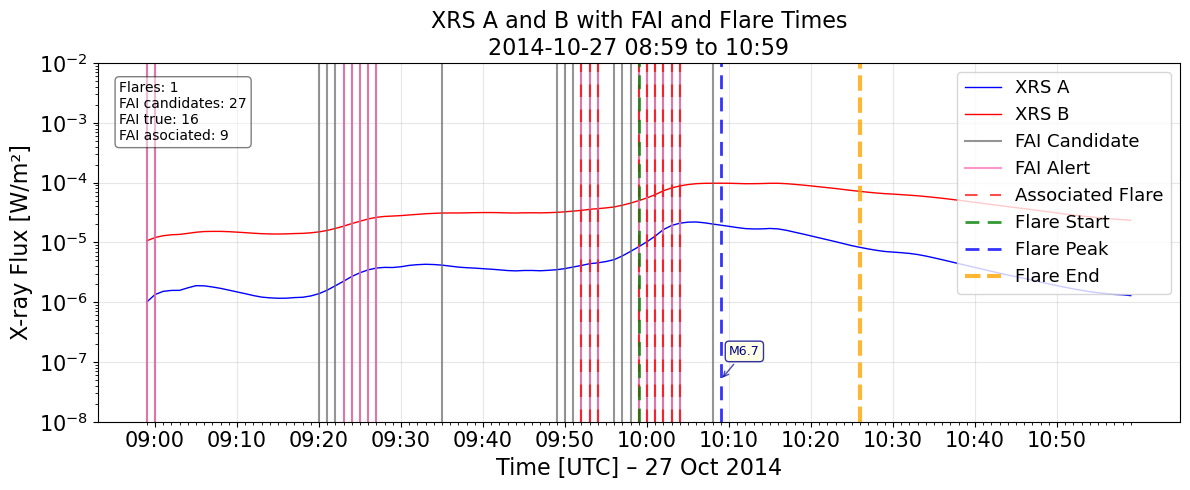

In [122]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2014-10-27 08:59:00",
                             flare_end_time="2014-10-27 10:59:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

Buscando datos entre: 2011-08-09 07:05:00 y 2011-08-09 09:05:00
Datos en df_plot: 121, FAI_assoc: 10, FAI_all: 14
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 14
FAI verdaderos en el intervalo: 10
FAI asociados a flares en el intervalo: 10


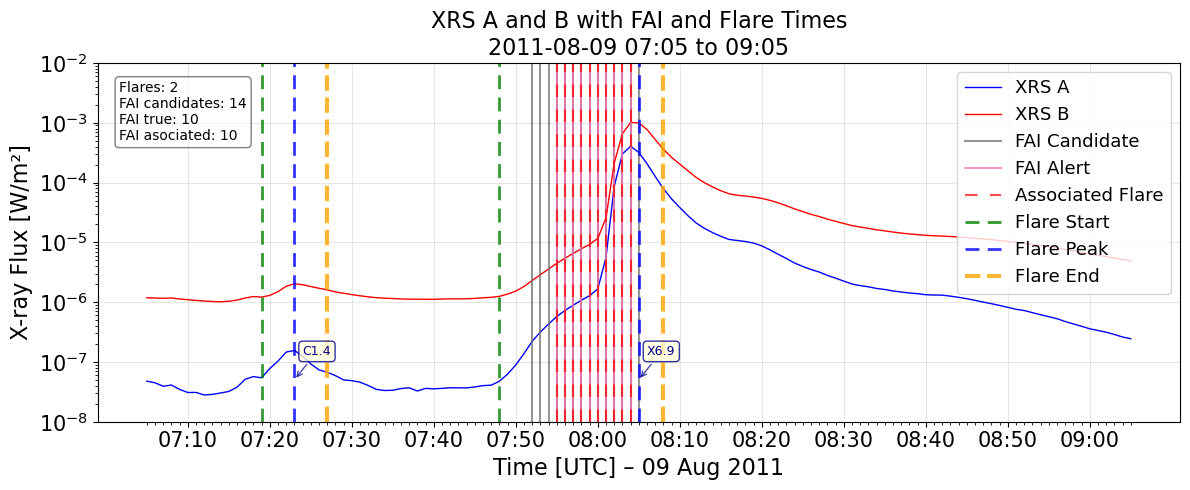

In [12]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2011-08-09 07:05:00",
                             flare_end_time="2011-08-09 09:05:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

Buscando datos entre: 2024-05-11 00:23:00 y 2024-05-11 02:23:00
Datos en df_plot: 121, FAI_assoc: 5, FAI_all: 11
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 11
FAI verdaderos en el intervalo: 5
FAI asociados a flares en el intervalo: 5


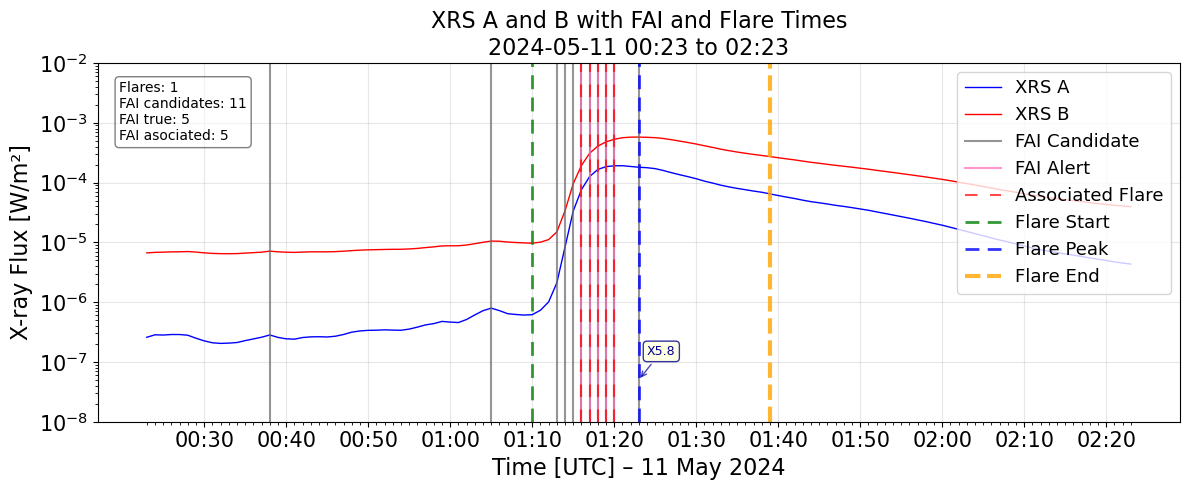

In [13]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2024-05-11 00:23:00",
                             flare_end_time="2024-05-11 02:23:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

# Flares con varias alertas de + a -

Buscando datos entre: 2024-12-30 07:44:00 y 2024-12-30 09:44:00


Datos en df_plot: 121, FAI_assoc: 1, FAI_all: 9
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 9
FAI verdaderos en el intervalo: 1
FAI asociados a flares en el intervalo: 1
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20241230_0744_0944.png


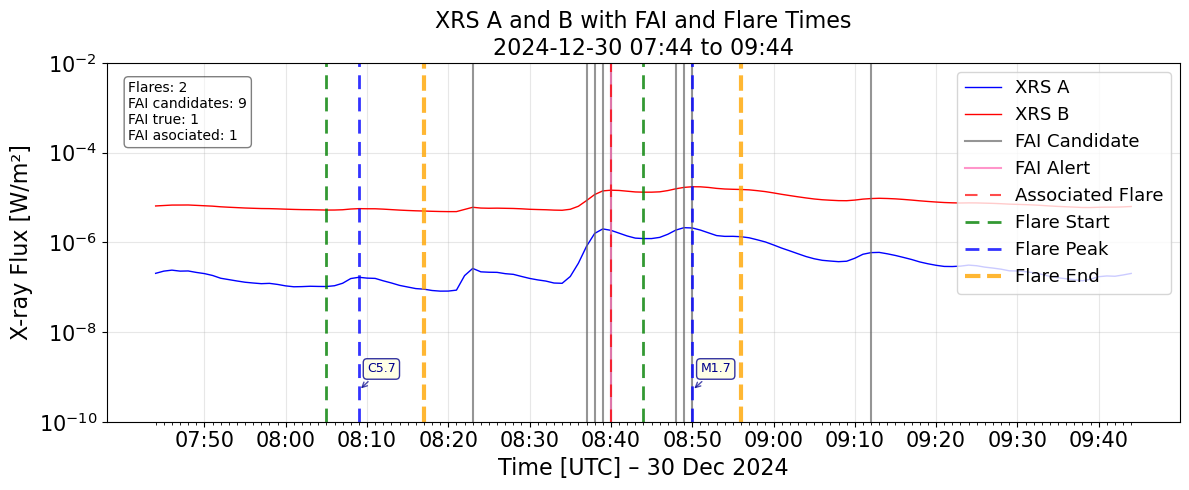

In [110]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2024-12-30 07:44:00",
                             flare_end_time="2024-12-30 09:44:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-10, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)




Buscando datos entre: 2000-11-08 22:00:00 y 2000-11-08 23:50:00
Datos en df_plot: 111, FAI_assoc: 17, FAI_all: 28
Fulguraciones en intervalo: 3
FAI candidatos en el intervalo: 28
FAI verdaderos en el intervalo: 17
FAI asociados a flares en el intervalo: 17


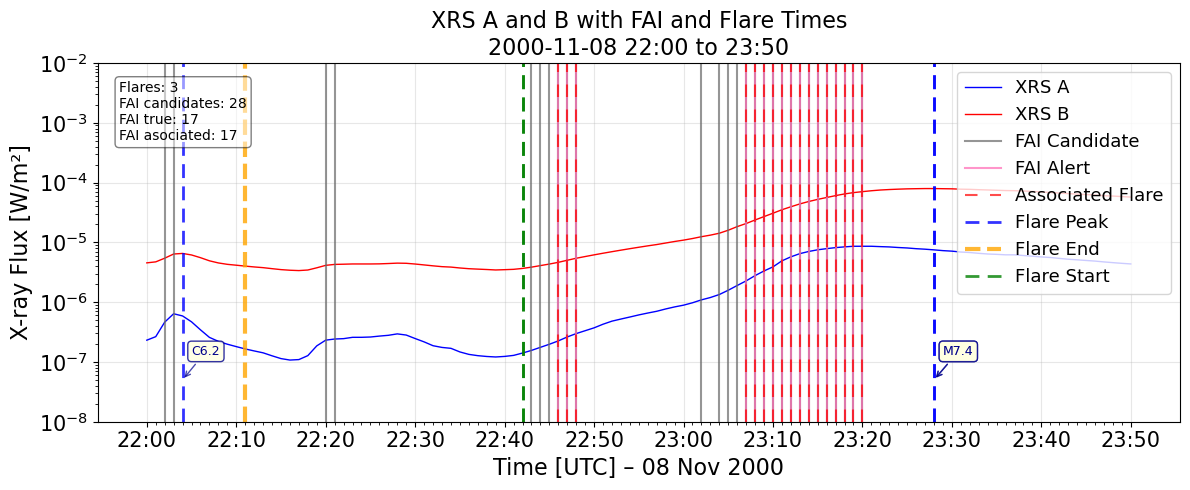

In [14]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2000-11-08 22:00:00",
                             flare_end_time="2000-11-08 23:50:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

Buscando datos entre: 2023-08-05 21:10:00 y 2023-08-05 23:10:00
Datos en df_plot: 121, FAI_assoc: 16, FAI_all: 20
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 20
FAI verdaderos en el intervalo: 16
FAI asociados a flares en el intervalo: 16
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20230805_2110_2310.png


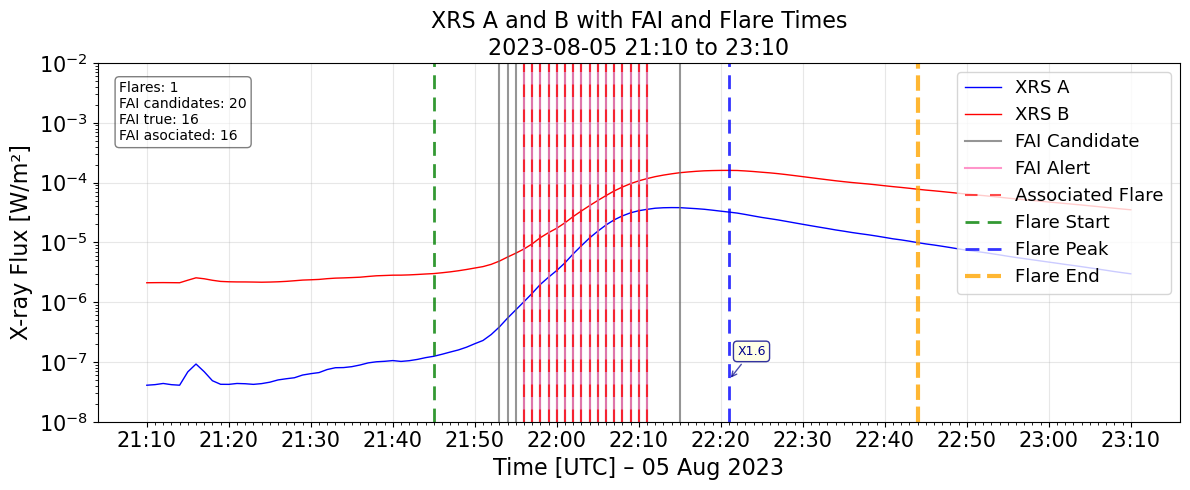

In [15]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2023-08-05 21:10:00",
                             flare_end_time="2023-08-05 23:10:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)



Buscando datos entre: 2002-08-04 08:20:00 y 2002-08-04 10:30:00
Datos en df_plot: 131, FAI_assoc: 16, FAI_all: 27
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 27
FAI verdaderos en el intervalo: 16
FAI asociados a flares en el intervalo: 16
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20020804_0820_1030.png


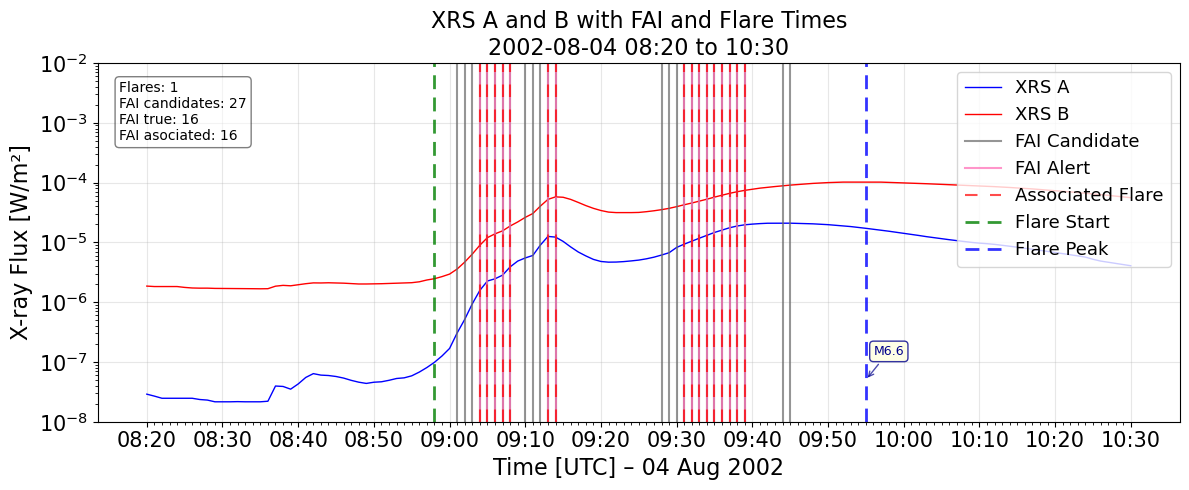

In [16]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2002-08-04 08:20:00",
                             flare_end_time="2002-08-04 10:30:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2014-10-25 16:00:00 y 2014-10-25 18:30:00
Datos en df_plot: 151, FAI_assoc: 15, FAI_all: 31
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 31
FAI verdaderos en el intervalo: 15
FAI asociados a flares en el intervalo: 15
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20141025_1600_1830.png


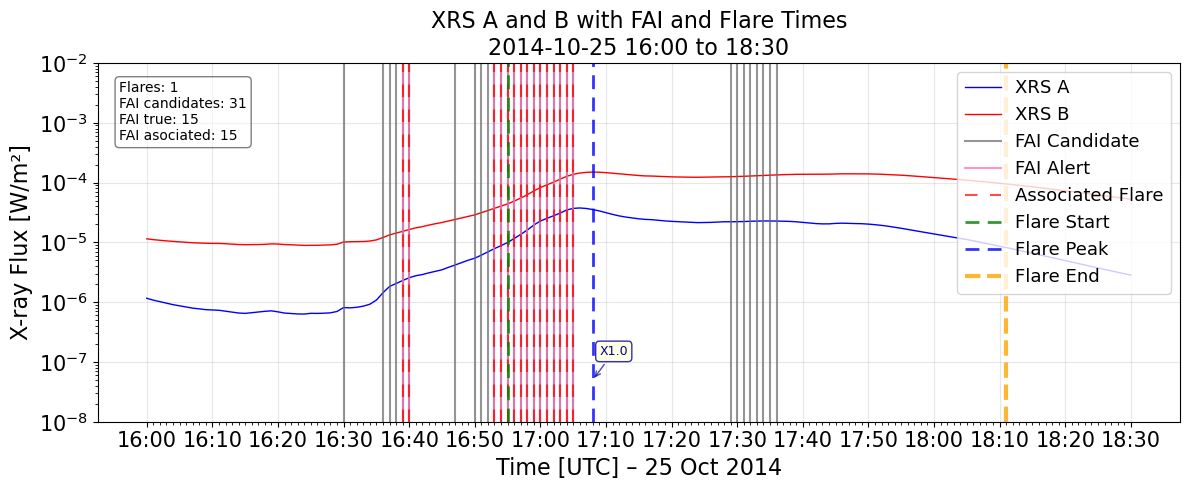

In [90]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2014-10-25 16:00:00",
                             flare_end_time="2014-10-25 18:30:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)


## alertas antes del start

Buscando datos entre: 1981-07-19 04:10:00 y 1981-07-19 06:40:00
Datos en df_plot: 151, FAI_assoc: 10, FAI_all: 30
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 30
FAI verdaderos en el intervalo: 10
FAI asociados a flares en el intervalo: 10
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19810719_0410_0640.png


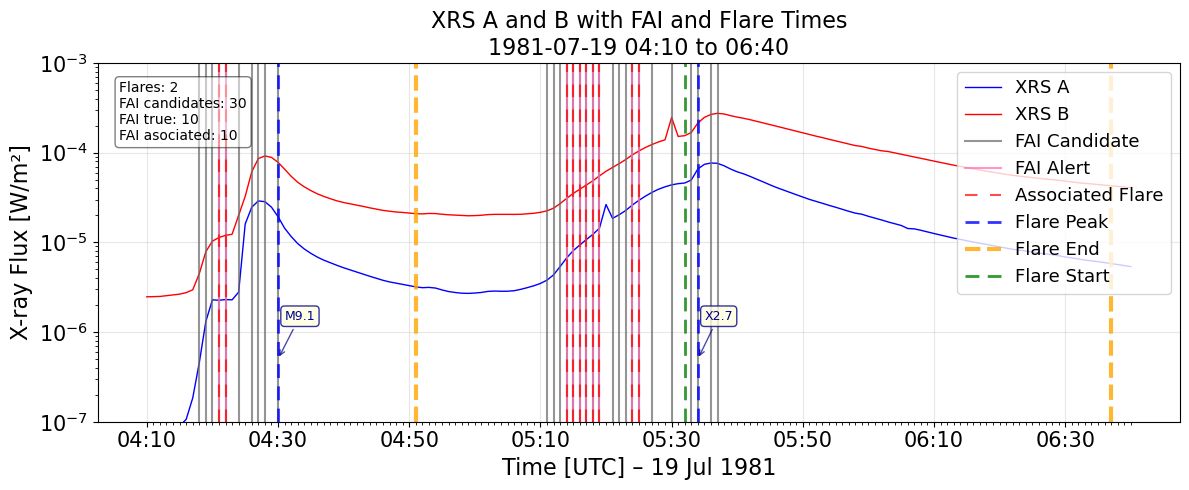

In [17]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="1981-07-19 04:10:00",
                             flare_end_time="1981-07-19 06:40:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-7, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2014-10-25 16:00:00 y 2014-10-25 18:30:00
Datos en df_plot: 151, FAI_assoc: 15, FAI_all: 31
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 31
FAI verdaderos en el intervalo: 15
FAI asociados a flares en el intervalo: 15
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20141025_1600_1830.png


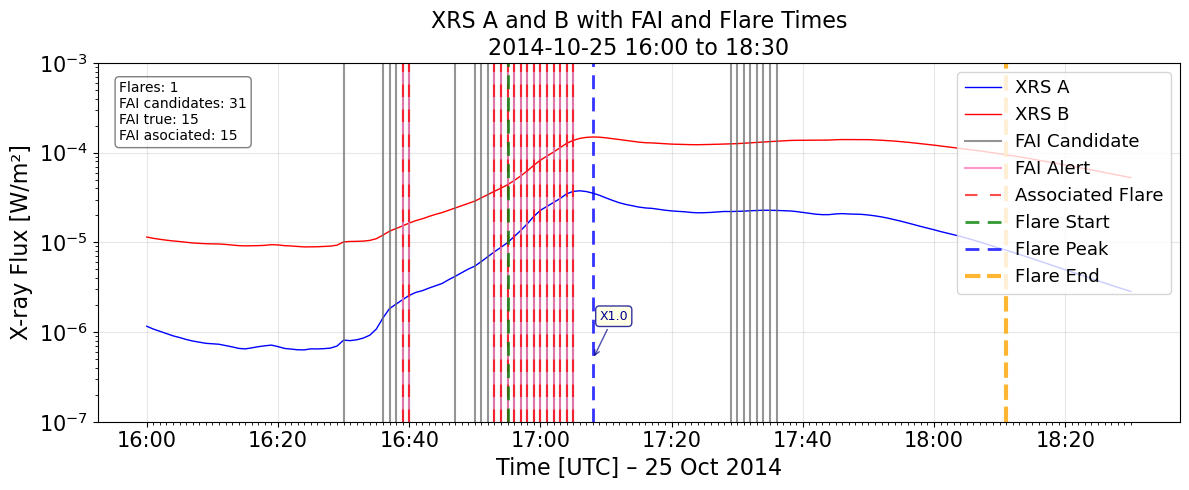

In [18]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2014-10-25 16:00:00",
                             flare_end_time="2014-10-25 18:30:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-7, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2005-07-07 14:50:00 y 2005-07-07 17:50:00
Datos en df_plot: 181, FAI_assoc: 11, FAI_all: 14
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 14
FAI verdaderos en el intervalo: 11
FAI asociados a flares en el intervalo: 11
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20050707_1450_1750.png


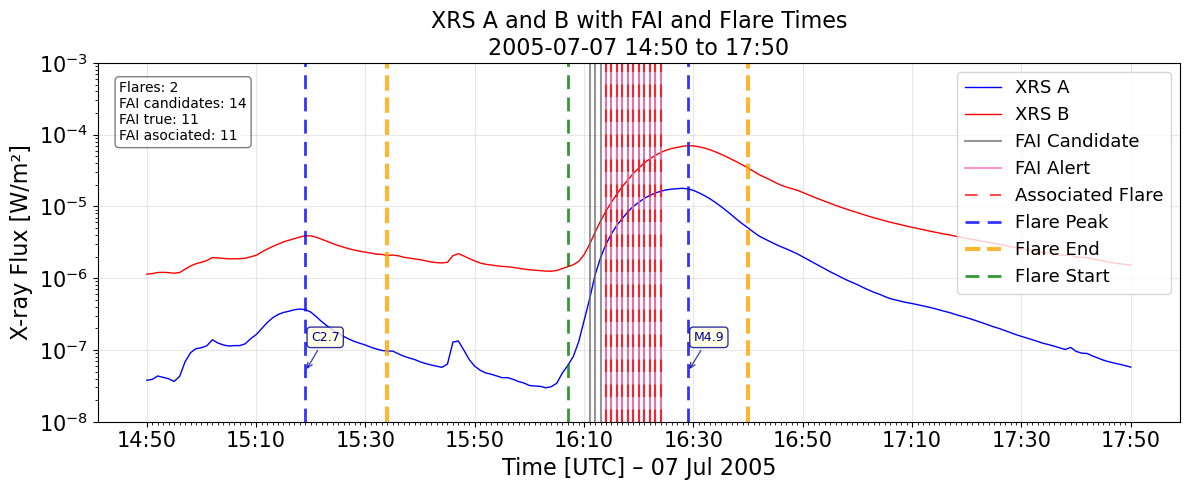

In [19]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2005-07-07 14:50:00",
                             flare_end_time="2005-07-07 17:50:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)


Buscando datos entre: 2014-10-27 09:00:00 y 2014-10-27 11:10:00
Datos en df_plot: 131, FAI_assoc: 15, FAI_all: 26
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 26
FAI verdaderos en el intervalo: 15
FAI asociados a flares en el intervalo: 9
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20141027_0900_1110.png


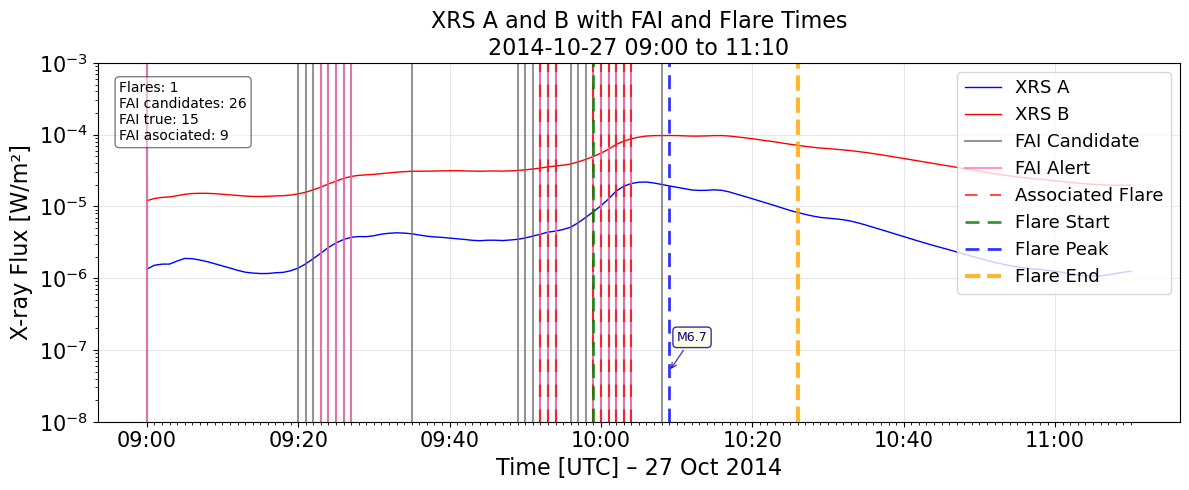

In [20]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2014-10-27 09:00:00",
                             flare_end_time="2014-10-27 11:10:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

## errores por revisar 

Buscando datos entre: 2025-02-02 21:36:00 y 2025-02-02 23:59:00
Datos en df_plot: 144, FAI_assoc: 3, FAI_all: 10
Fulguraciones en intervalo: 6
FAI candidatos en el intervalo: 10
FAI verdaderos en el intervalo: 3
FAI asociados a flares en el intervalo: 3
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20250202_2136_2359.png


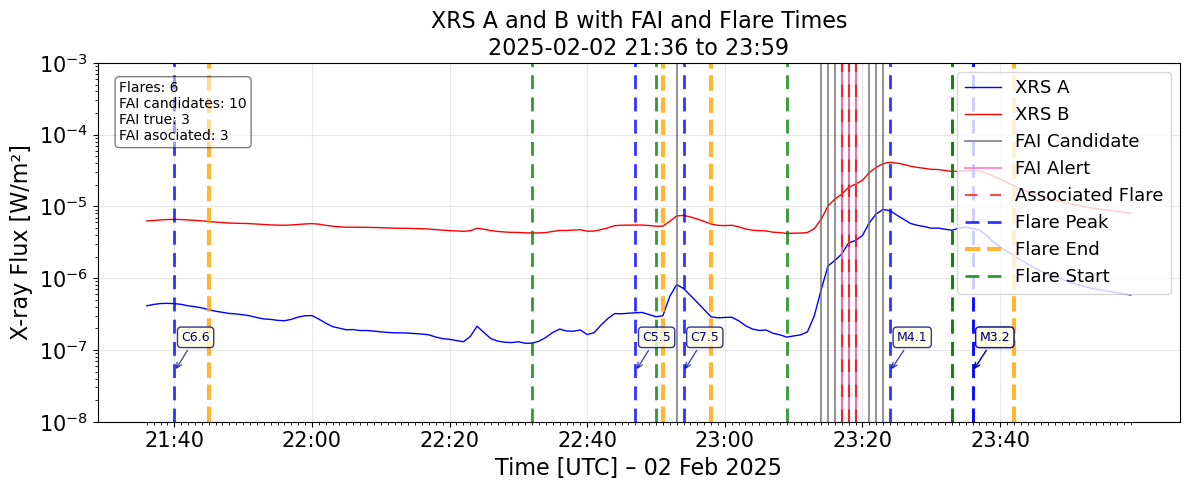

In [21]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2025-02-02 21:36:00",  # revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo C
                             flare_end_time="2025-02-02 23:59:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2023-04-14 14:59:00 y 2023-04-14 17:59:00
Datos en df_plot: 181, FAI_assoc: 3, FAI_all: 6
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 6
FAI verdaderos en el intervalo: 3
FAI asociados a flares en el intervalo: 3
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20230414_1459_1759.png


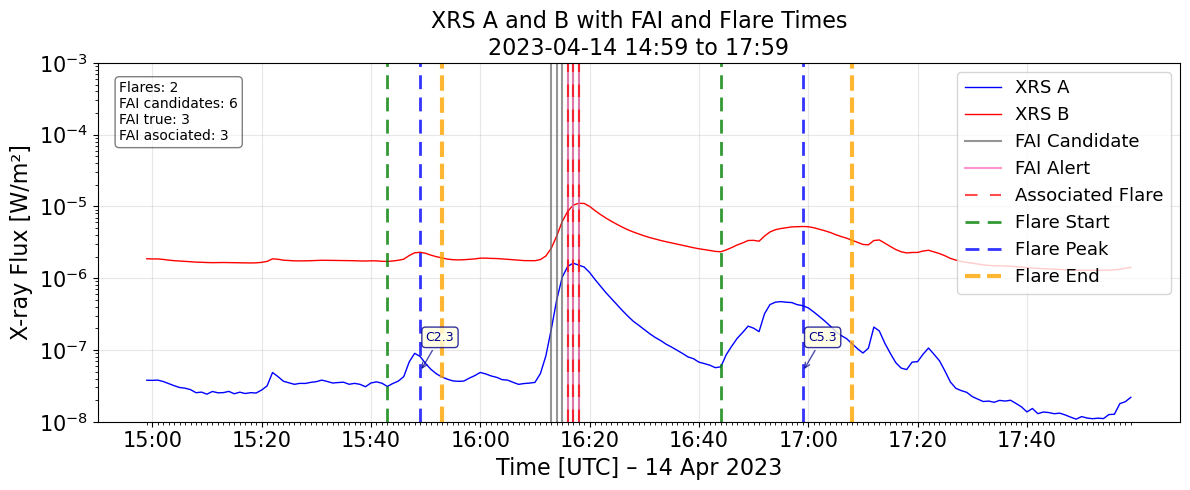

In [22]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid, # revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo C
                             flare_start_time="2023-04-14 14:59:00",
                             flare_end_time="2023-04-14 17:59:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2001-06-13 10:56:00 y 2001-06-13 12:56:00
Datos en df_plot: 121, FAI_assoc: 4, FAI_all: 11
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 11
FAI verdaderos en el intervalo: 4
FAI asociados a flares en el intervalo: 4
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20010613_1056_1256.png


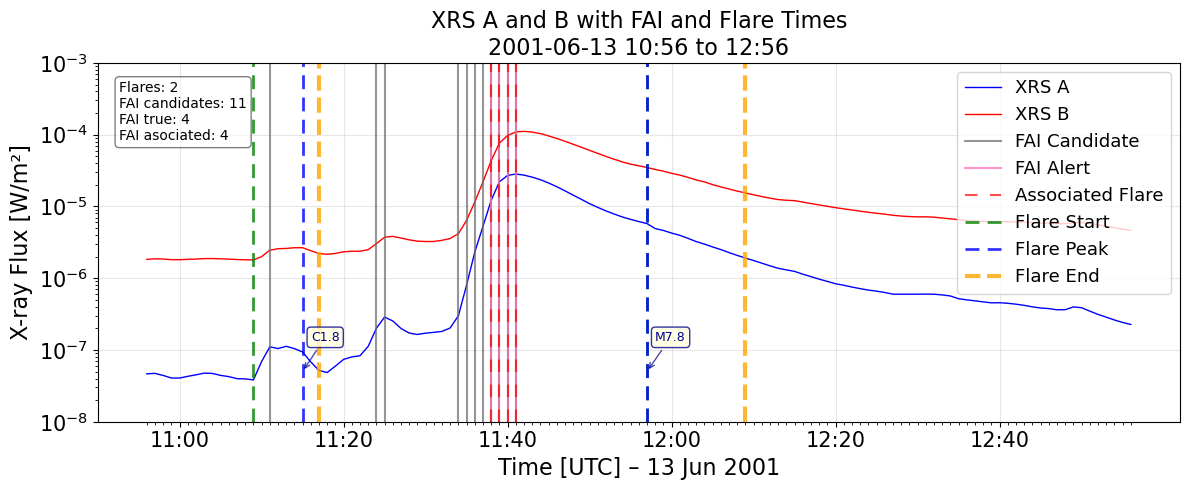

In [23]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid, # revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo C 
                             flare_start_time="2001-06-13 10:56:00",
                             flare_end_time="2001-06-13 12:56:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2024-07-13 21:20:00 y 2024-07-13 23:59:00
Datos en df_plot: 160, FAI_assoc: 7, FAI_all: 12
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 12
FAI verdaderos en el intervalo: 7
FAI asociados a flares en el intervalo: 7
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20240713_2120_2359.png


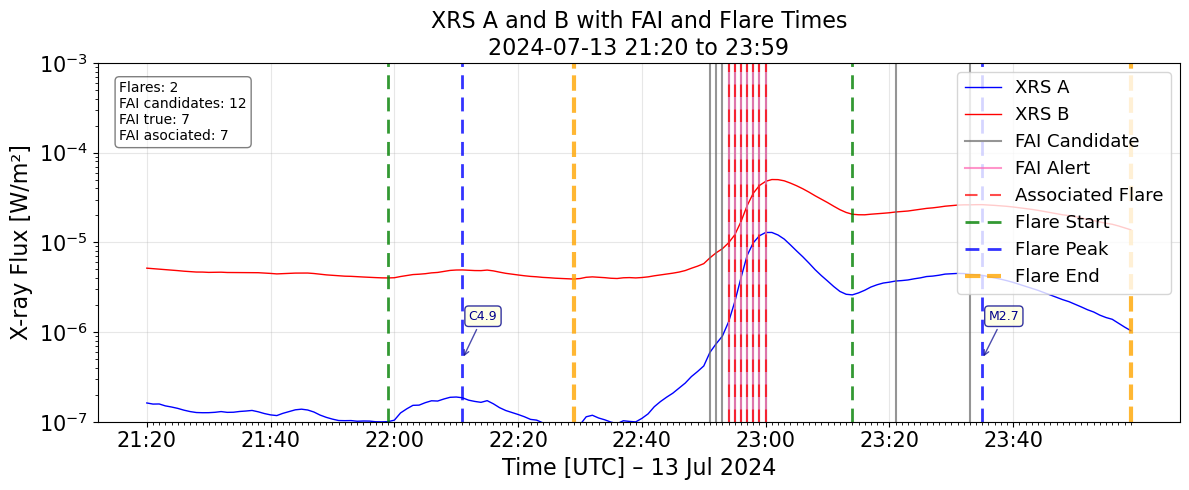

In [24]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid, # revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo C 
                             flare_start_time="2024-07-13 21:20:00",
                             flare_end_time="2024-07-13 23:59:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-7, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2024-08-09 20:03:00 y 2024-08-09 23:03:00


Datos en df_plot: 181, FAI_assoc: 6, FAI_all: 17
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 17
FAI verdaderos en el intervalo: 6
FAI asociados a flares en el intervalo: 6
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20240809_2003_2303.png


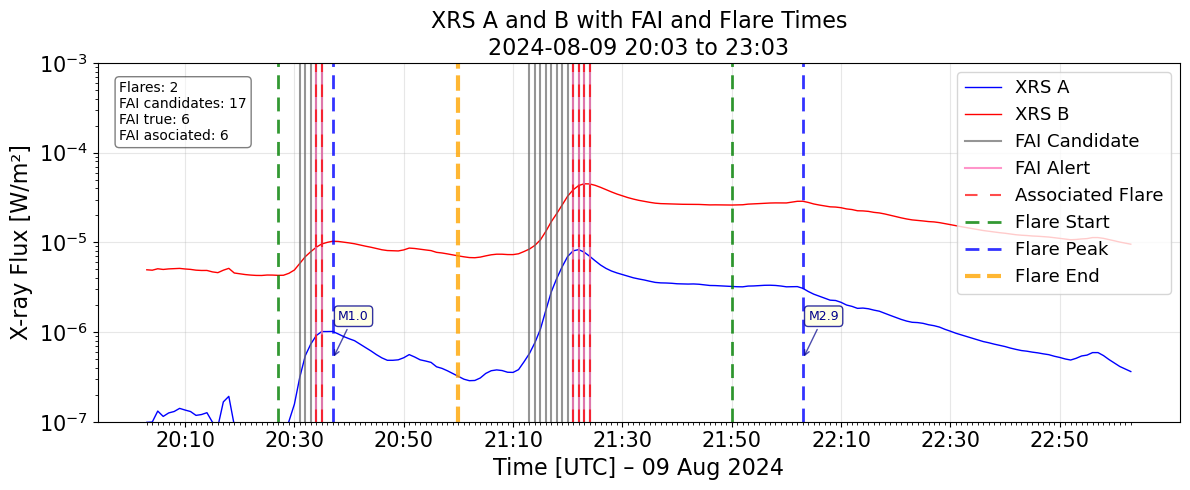

In [25]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid, # revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo M
                             flare_start_time="2024-08-09 20:03:00",
                             flare_end_time="2024-08-09 23:03:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-7, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2023-07-26 15:13:00 y 2023-07-26 17:13:00
Datos en df_plot: 121, FAI_assoc: 5, FAI_all: 11
Fulguraciones en intervalo: 3
FAI candidatos en el intervalo: 11
FAI verdaderos en el intervalo: 5
FAI asociados a flares en el intervalo: 5
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20230726_1513_1713.png


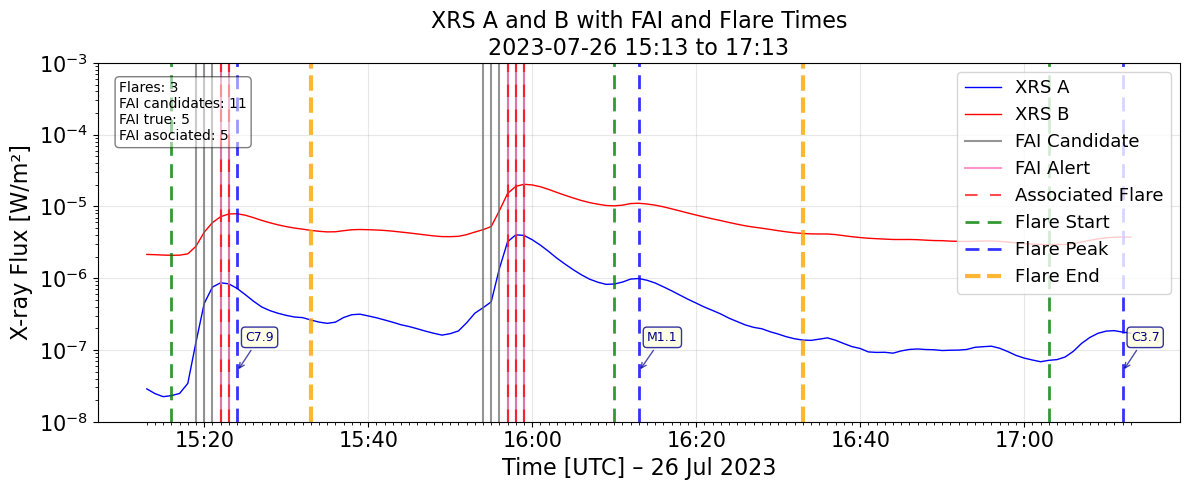

In [26]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,# revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo C
                             flare_start_time="2023-07-26 15:13:00",
                             flare_end_time="2023-07-26 17:13:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2022-12-15 00:08:00 y 2022-12-15 03:08:00
Datos en df_plot: 181, FAI_assoc: 4, FAI_all: 12
Fulguraciones en intervalo: 5
FAI candidatos en el intervalo: 12
FAI verdaderos en el intervalo: 4
FAI asociados a flares en el intervalo: 4
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20221215_0008_0308.png


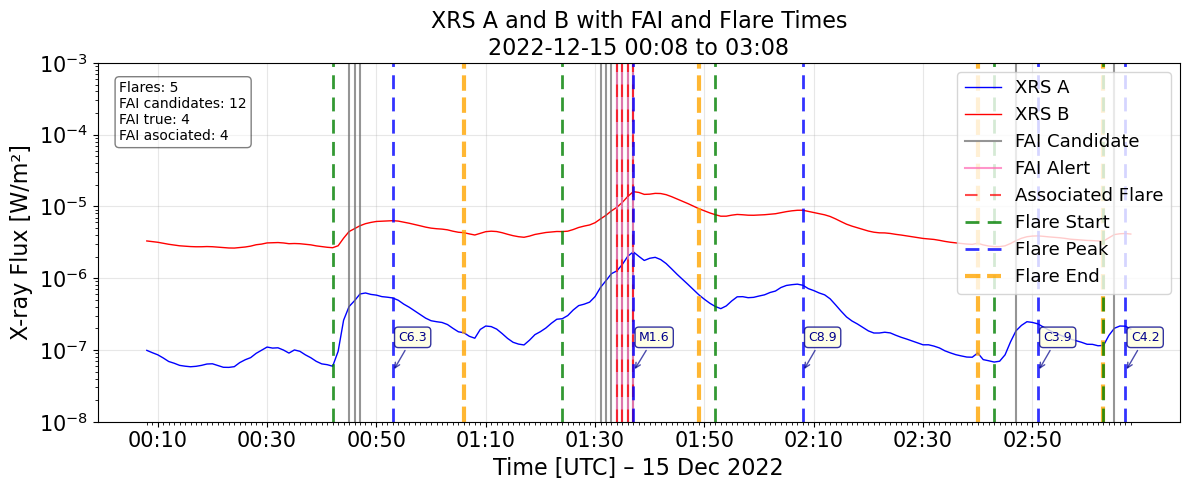

In [27]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2022-12-15 00:08:00", # revisar con _all porque las líneas pertenecen a un flare anterior / debico al flare tipo C
                             flare_end_time="2022-12-15 03:08:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-8, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

## Analysis flare by flare - Flares sin alerta asociada

### flares clase X5+

Buscando datos entre: 1991-03-22 21:45:00 y 1991-03-22 23:45:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 4
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 4
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19910322_2145_2345.png


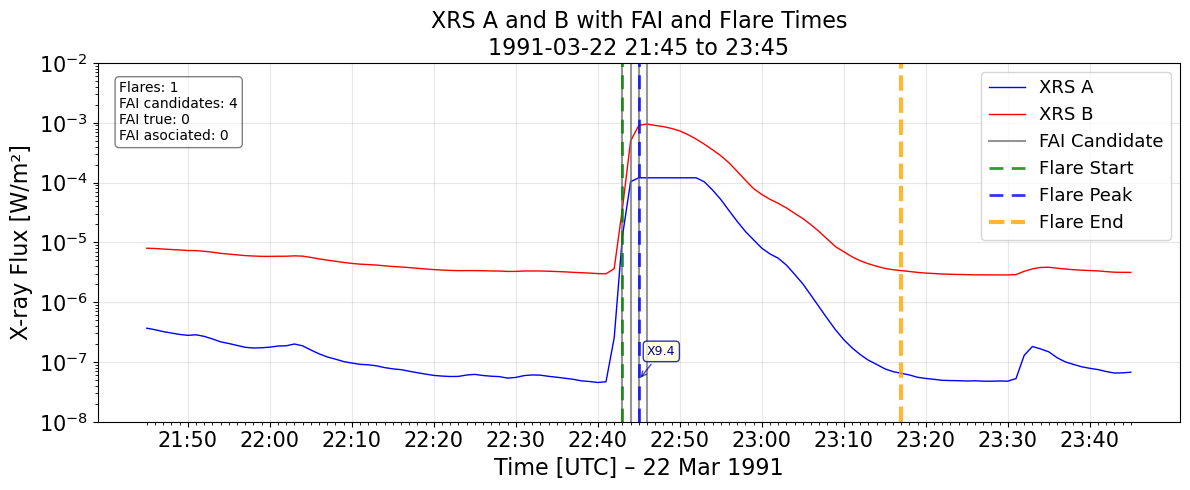

In [28]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="1991-03-22 21:45:00",
                             flare_end_time="1991-03-22 23:45:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1991-03-07 06:48:00 y 1991-03-07 08:48:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 2
Fulguraciones en intervalo: 3
FAI candidatos en el intervalo: 2
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19910307_0648_0848.png


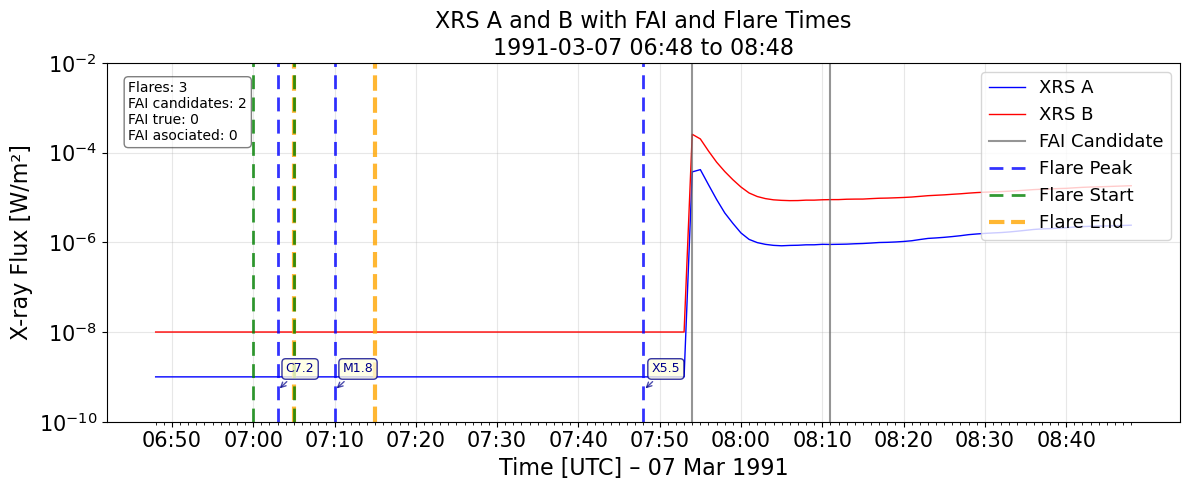

In [29]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="1991-03-07 06:48:00",
                             flare_end_time="1991-03-07 08:48:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-10, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

### Flares X1-4.9

Buscando datos entre: 1984-05-19 21:00:00 y 1984-05-19 23:00:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 3
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 3
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19840519_2100_2300.png


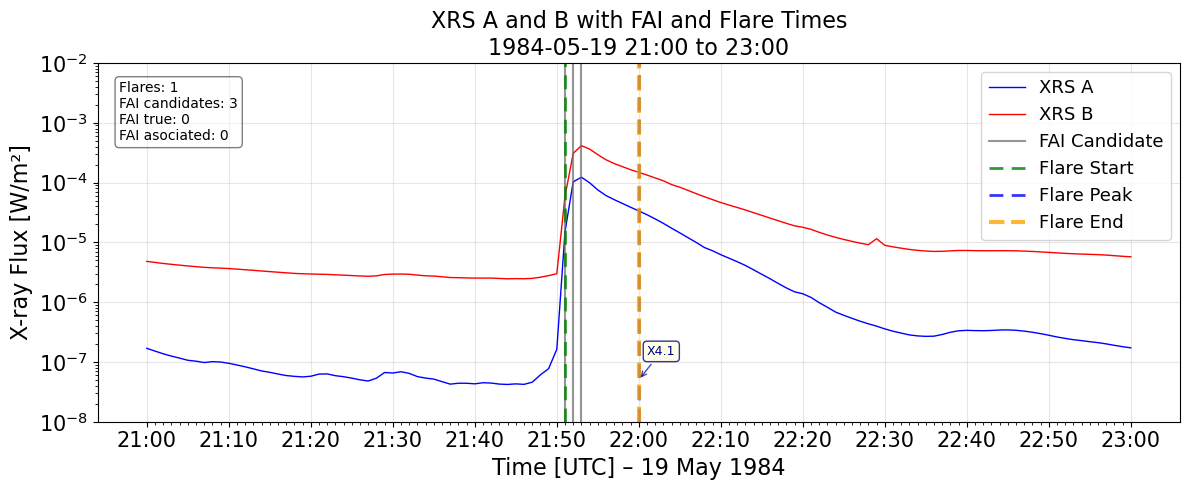

In [30]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1984-05-19 21:00:00",
                             flare_end_time="1984-05-19 23:00:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1989-06-15 17:00:00 y 1989-06-15 20:14:00
Datos en df_plot: 195, FAI_assoc: 2, FAI_all: 23
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 23
FAI verdaderos en el intervalo: 2
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19890615_1700_2014.png


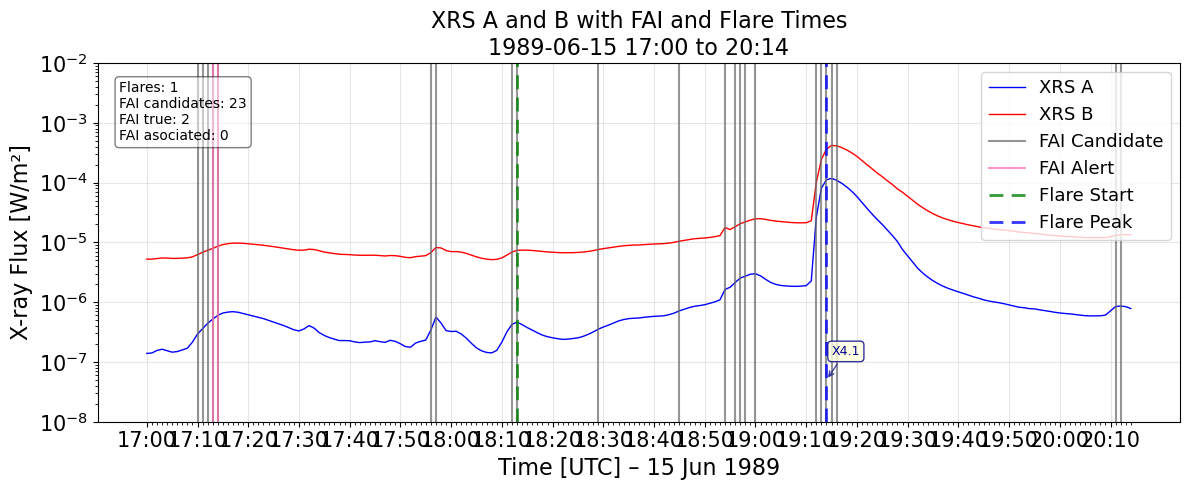

In [31]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1989-06-15 17:00:00",
                             flare_end_time="1989-06-15 20:14:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1989-11-21 12:46:00 y 1989-11-21 14:46:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 7
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 7
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19891121_1246_1446.png


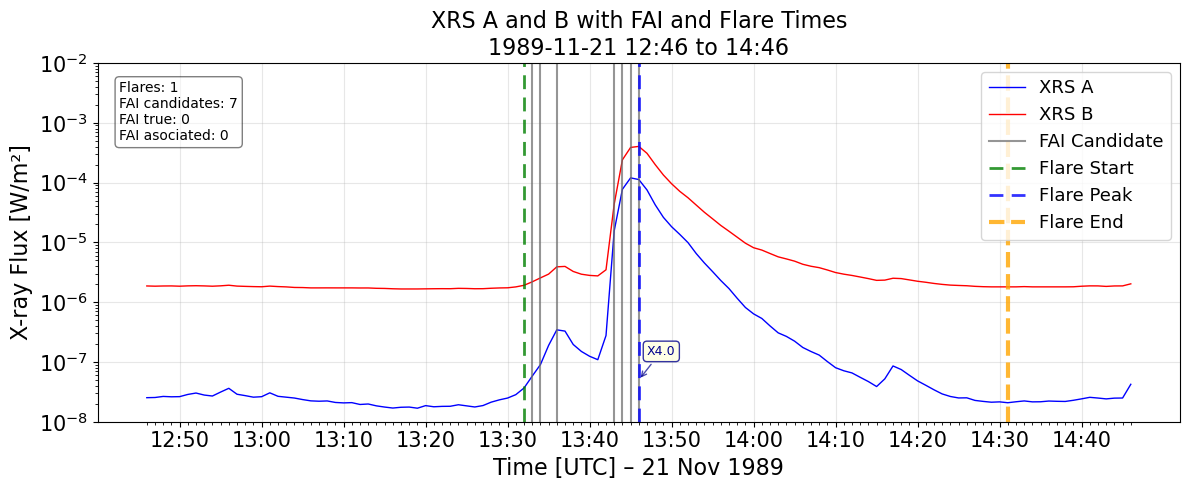

In [32]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1989-11-21 12:46:00",
                             flare_end_time="1989-11-21 14:46:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2004-07-16 12:30:00 y 2004-07-16 14:20:00
Datos en df_plot: 111, FAI_assoc: 2, FAI_all: 11
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 11
FAI verdaderos en el intervalo: 2
FAI asociados a flares en el intervalo: 2
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20040716_1230_1420.png


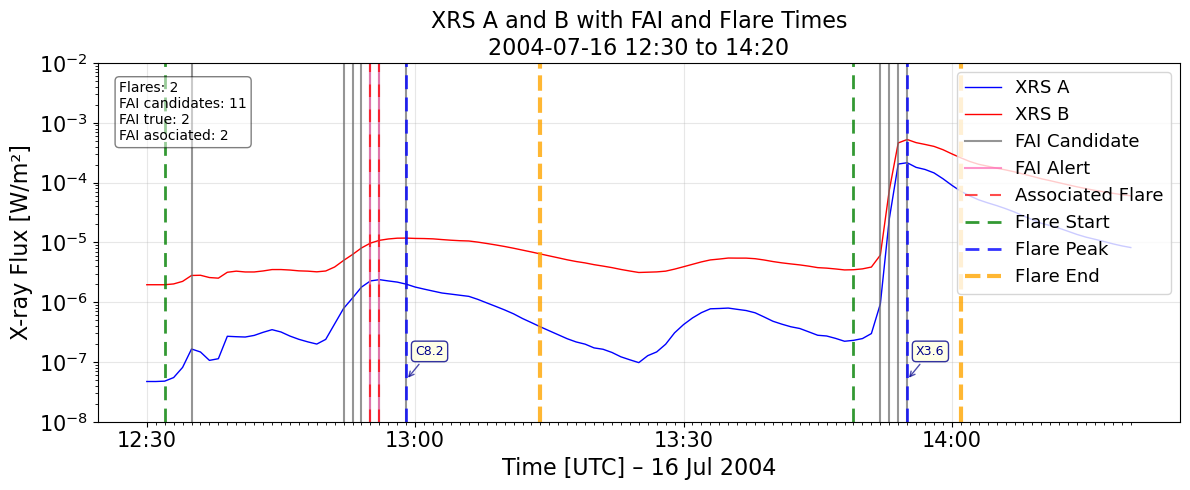

In [33]:

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2004-07-16 12:30:00",
                             flare_end_time="2004-07-16 14:20:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)


Buscando datos entre: 1989-08-17 00:35:00 y 1989-08-17 02:35:00
Datos en df_plot: 121, FAI_assoc: 3, FAI_all: 14
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 14
FAI verdaderos en el intervalo: 3
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19890817_0035_0235.png


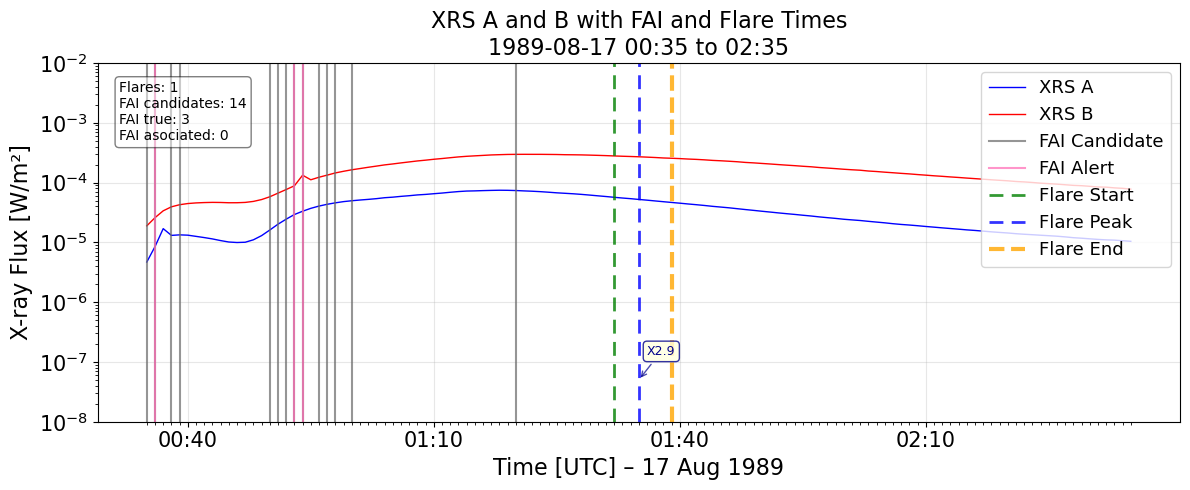

In [34]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1989-08-17 00:35:00",
                             flare_end_time="1989-08-17 02:35:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1991-03-07 22:19:00 y 1991-03-07 23:59:00
Datos en df_plot: 101, FAI_assoc: 1, FAI_all: 7
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 7
FAI verdaderos en el intervalo: 1
FAI asociados a flares en el intervalo: 1
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19910307_2219_2359.png


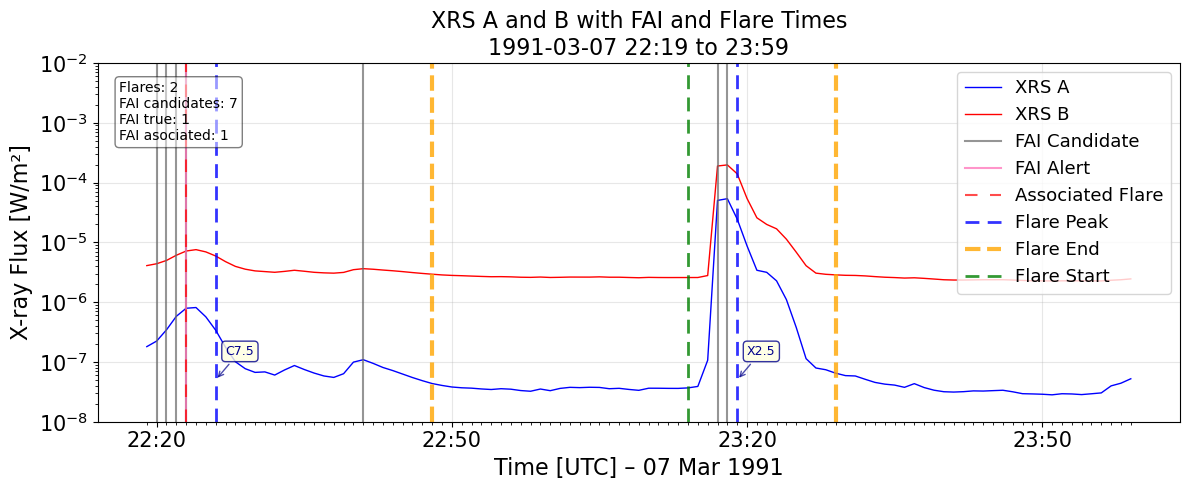

In [35]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1991-03-07 22:19:00",
                             flare_end_time="1991-03-07 23:59:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1980-11-12 03:50:00 y 1980-11-12 05:50:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 9
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 9
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19801112_0350_0550.png


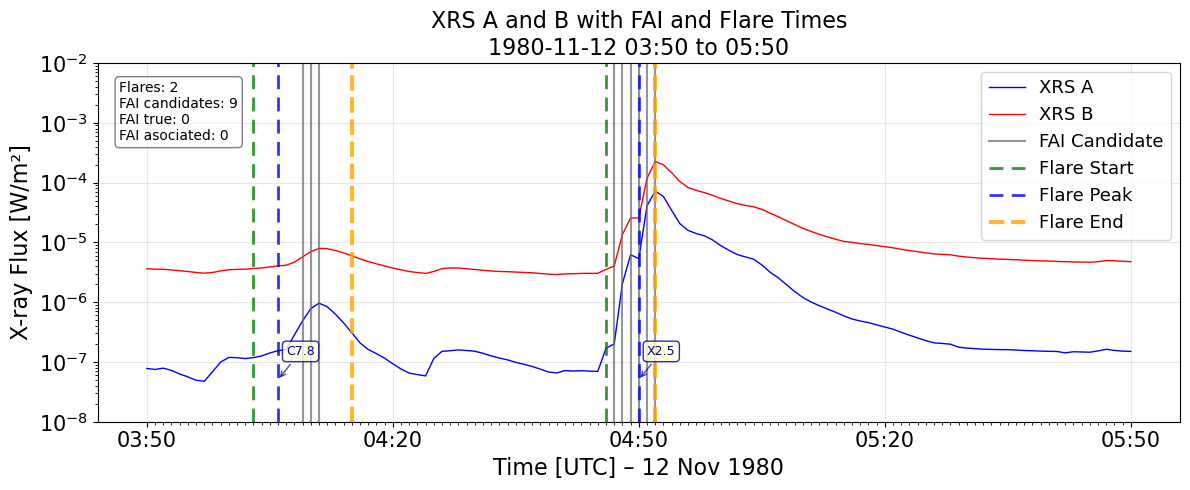

In [36]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1980-11-12 03:50:00",
                             flare_end_time="1980-11-12 05:50:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2011-02-15 00:45:00 y 2011-02-15 02:45:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 10
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 10
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20110215_0045_0245.png


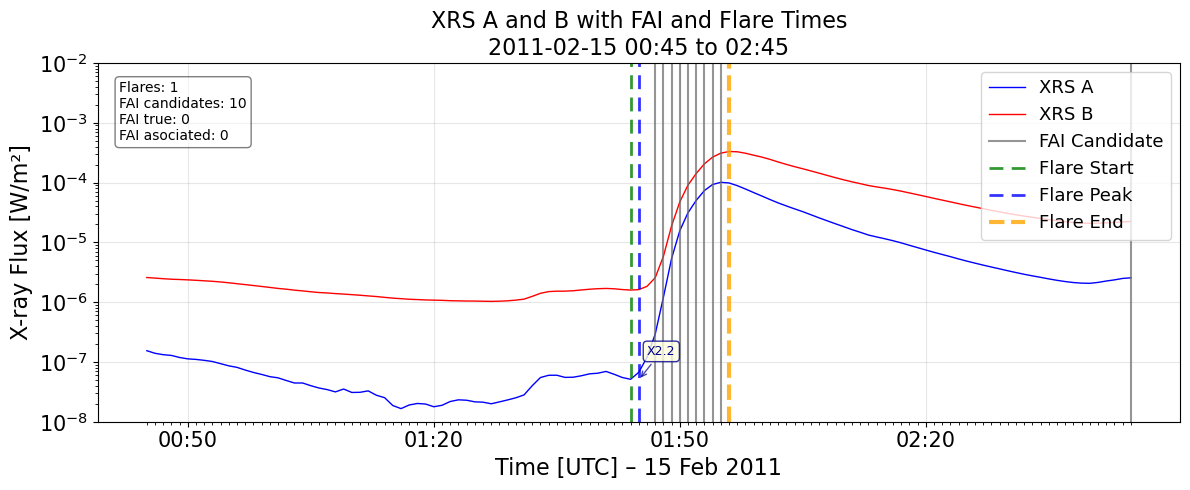

In [37]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2011-02-15 00:45:00",
                             flare_end_time="2011-02-15 02:45:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2014-06-10 11:00:00 y 2014-06-10 13:00:00
Datos en df_plot: 121, FAI_assoc: 9, FAI_all: 16
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 16
FAI verdaderos en el intervalo: 9
FAI asociados a flares en el intervalo: 9
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20140610_1100_1300.png


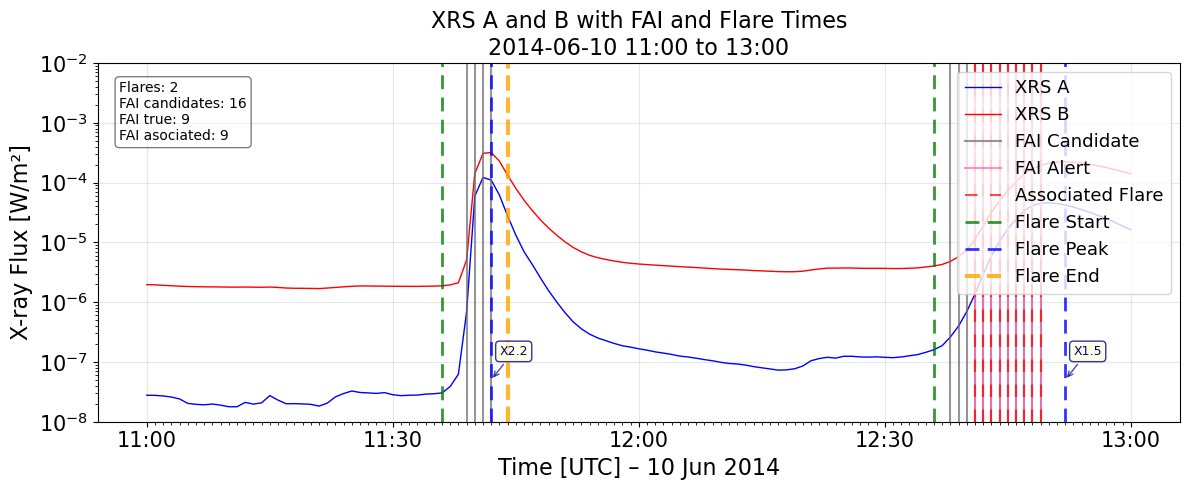

In [38]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2014-06-10 11:00:00",
                             flare_end_time="2014-06-10 13:00:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1991-10-24 01:40:00 y 1991-10-24 03:40:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 4
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 4
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19911024_0140_0340.png


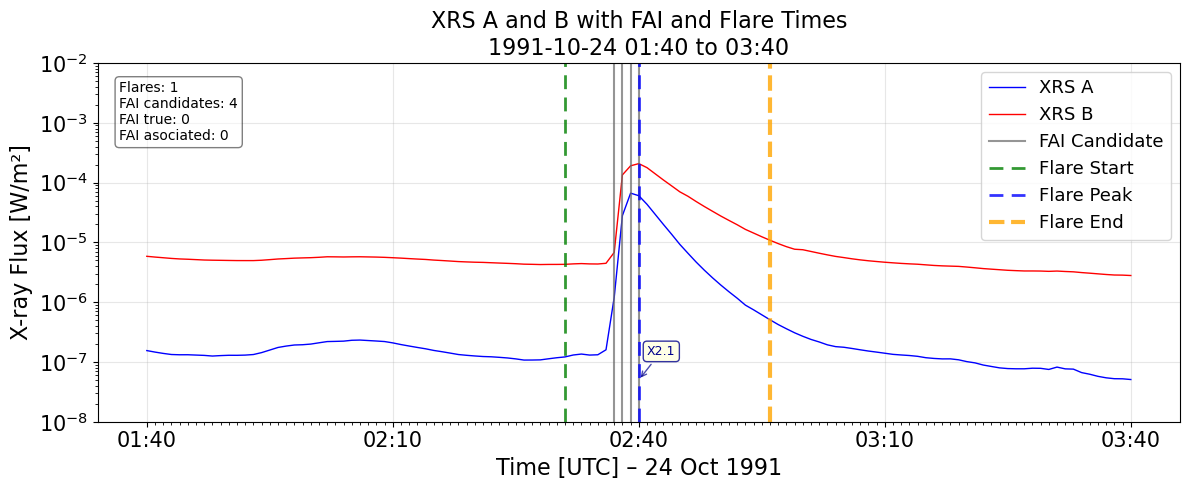

In [39]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1991-10-24 01:40:0",
                             flare_end_time="1991-10-24 03:40:0", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

In [40]:
# faltan mas de la lista

Buscando datos entre: 2023-01-10 21:47:00 y 2023-01-10 23:47:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 5
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 5
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20230110_2147_2347.png


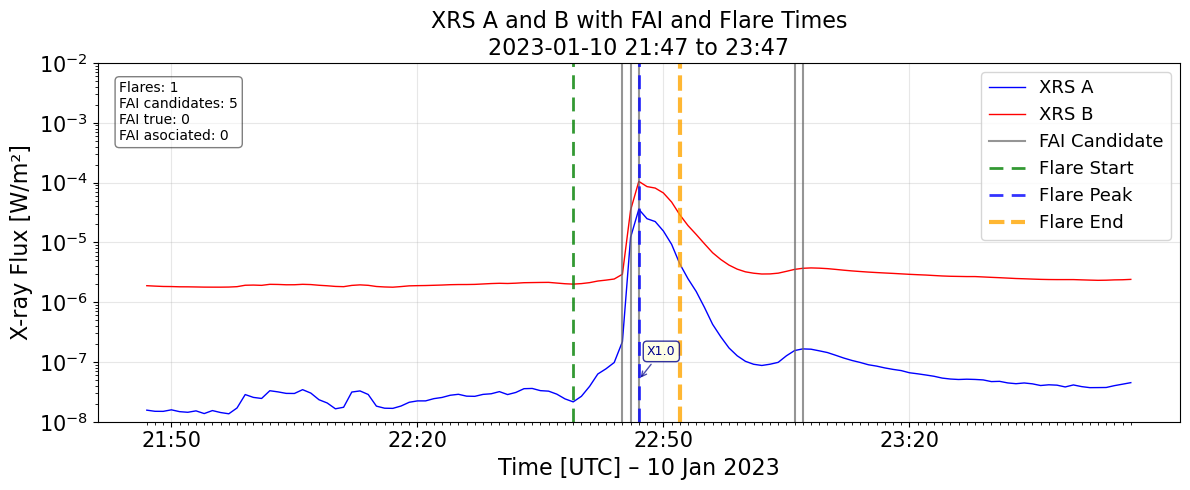

In [41]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2023-01-10 21:47:00",
                             flare_end_time="2023-01-10 23:47:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

# M

Buscando datos entre: 1991-10-24 21:36:00 y 1991-10-24 23:36:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 8
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 8
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19911024_2136_2336.png


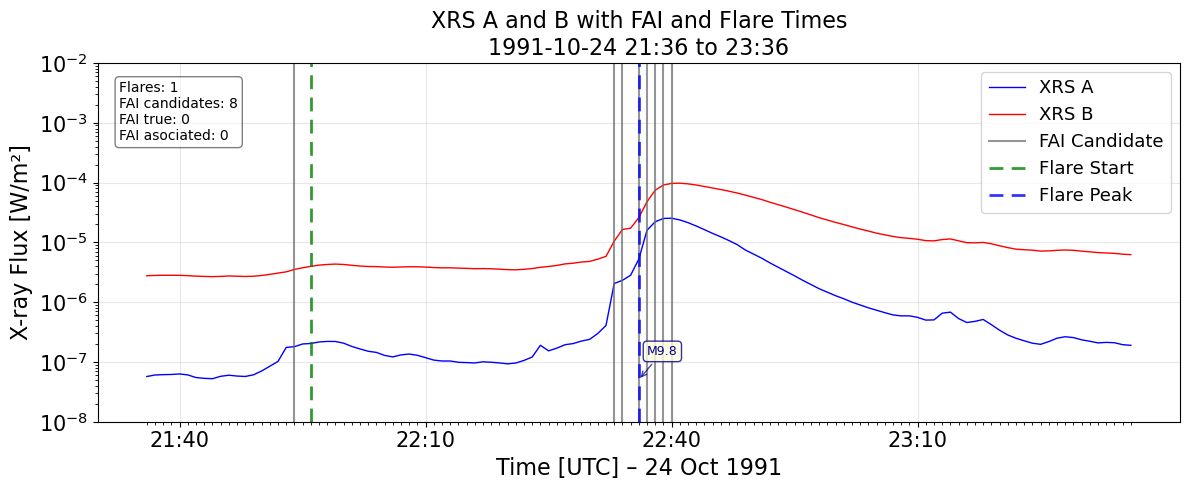

In [42]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1991-10-24 21:36:00",
                             flare_end_time="1991-10-24 23:36:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)



Buscando datos entre: 1989-11-08 17:10:00 y 1989-11-08 19:40:00
Datos en df_plot: 151, FAI_assoc: 2, FAI_all: 22
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 22
FAI verdaderos en el intervalo: 2
FAI asociados a flares en el intervalo: 2
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19891108_1710_1940.png


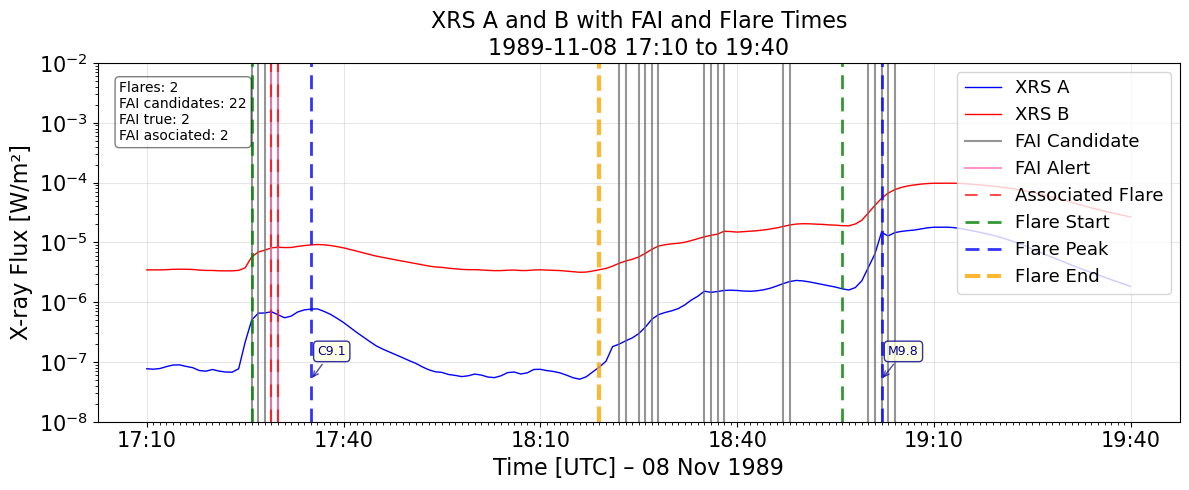

In [43]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1989-11-08 17:10:00",
                             flare_end_time="1989-11-08 19:40:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1999-08-20 22:10:00 y 1999-08-20 23:50:00
Datos en df_plot: 101, FAI_assoc: 0, FAI_all: 5
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 5
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19990820_2210_2350.png


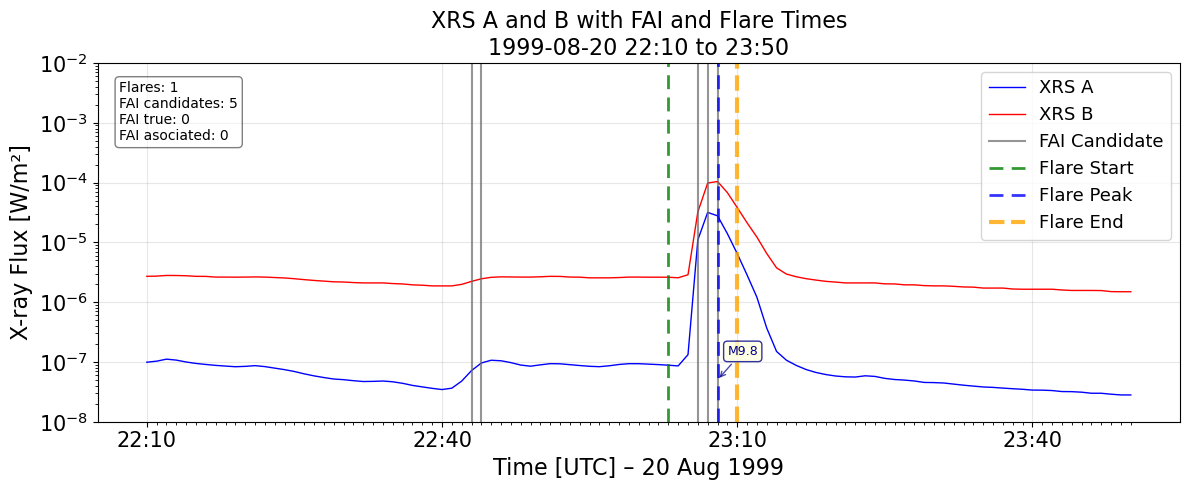

In [44]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1999-08-20 22:10:00",
                             flare_end_time="1999-08-20 23:50:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 1980-11-13 00:00:00 y 1980-11-13 01:40:00
Datos en df_plot: 101, FAI_assoc: 0, FAI_all: 9
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 9
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_19801113_0000_0140.png


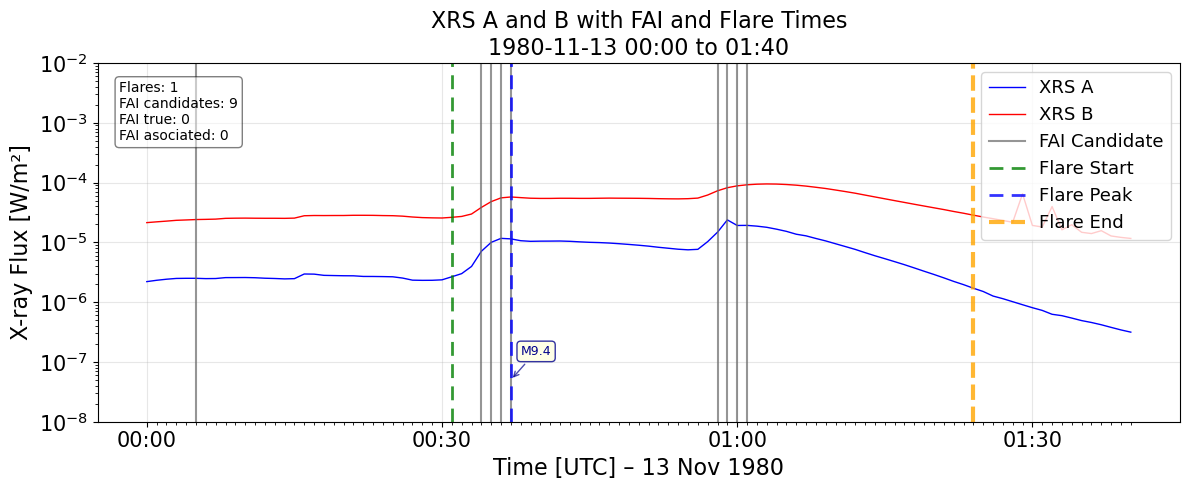

In [45]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1980-11-13 00:00:00",
                             flare_end_time="1980-11-13 01:40:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2011-07-30 01:10:00 y 2011-07-30 03:10:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 3
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 3
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20110730_0110_0310.png


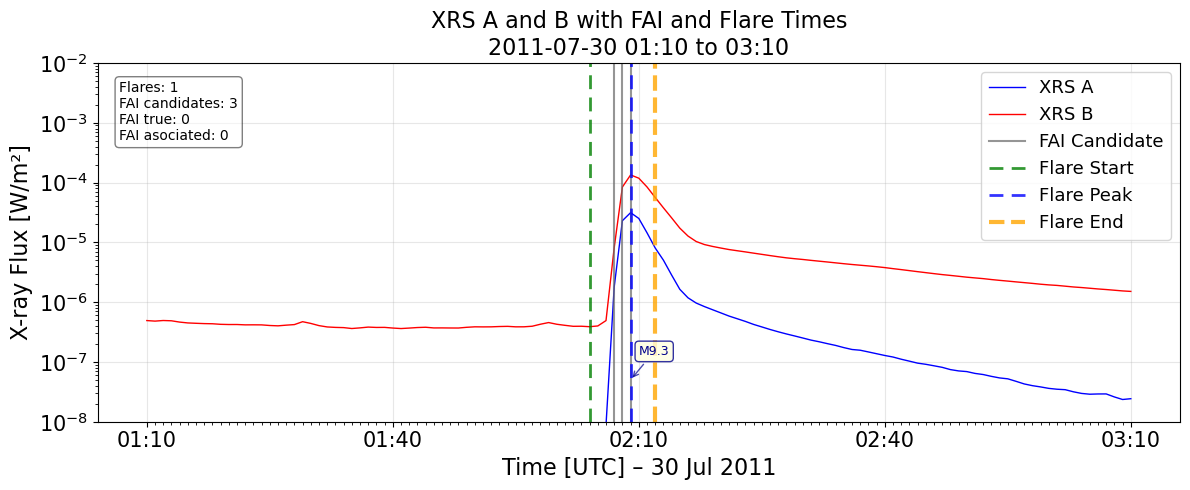

In [46]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2011-07-30 01:10:00",
                             flare_end_time="2011-07-30 03:10:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

Buscando datos entre: 2014-03-12 21:34:00 y 2014-03-12 23:34:00
Datos en df_plot: 121, FAI_assoc: 0, FAI_all: 4
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 4
FAI verdaderos en el intervalo: 0
FAI asociados a flares en el intervalo: 0
✅ Gráfica guardada en: Data_for_16752_days/Analysis_FAI/Analysis_FAI_ABCMX_T8-35_dEM0d015_dur4min/FlarebyFlare_filteredend_nooverlap_W30min/FAI_20140312_2134_2334.png


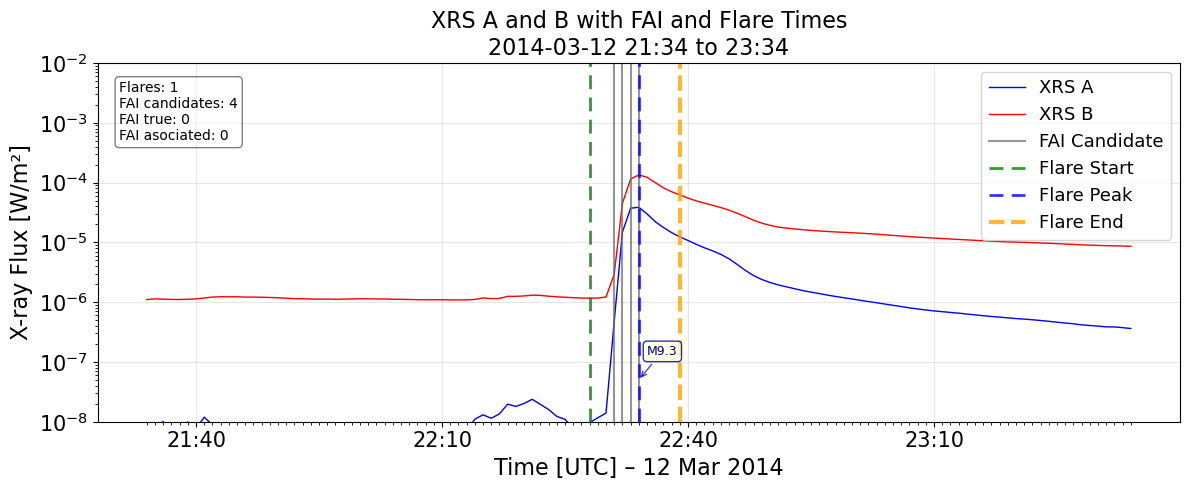

In [47]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2014-03-12 21:34:00",
                             flare_end_time="2014-03-12 23:34:000", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='30min',
                             ymin=1e-8, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=True,
                             annotate_counts=True)

In [48]:
# falta mas

## FAIs no asociados

### 1980

Buscando datos entre: 1980-04-26 04:30:00 y 1980-04-26 08:35:00
Datos en df_plot: 246, FAI_assoc: 2, FAI_all: 8
Fulguraciones en intervalo: 0
FAI candidatos en el intervalo: 8
FAI verdaderos en el intervalo: 2
FAI asociados a flares en el intervalo: 0


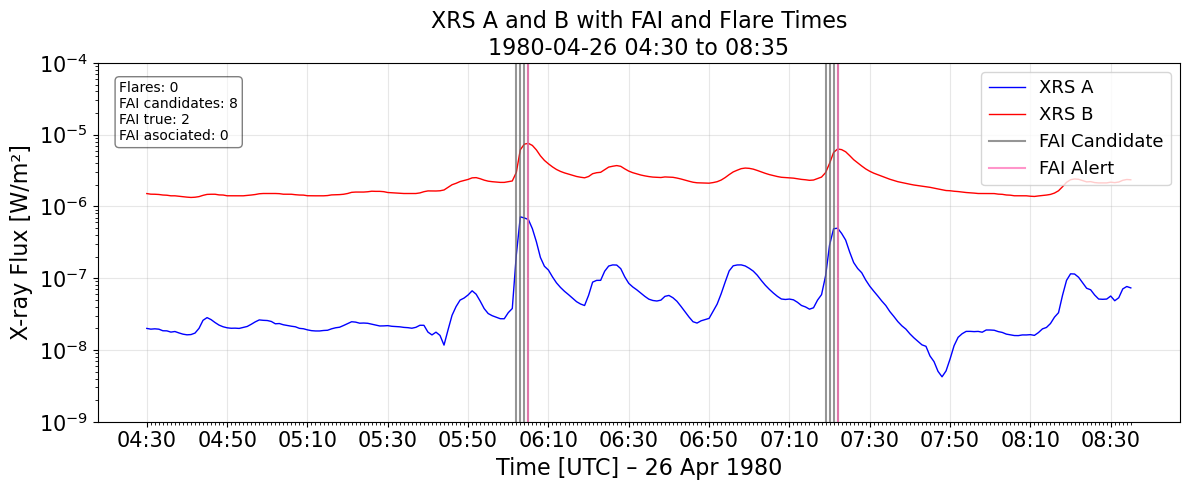

In [49]:
plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="1980-04-26 04:30:00",
                             flare_end_time="1980-04-26 08:35:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-9, ymax=1e-4,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)


## con varios FAIs consecutivos

Buscando datos entre: 2025-11-09 06:30:00 y 2025-11-09 08:11:00
Datos en df_plot: 102, FAI_assoc: 15, FAI_all: 20
Fulguraciones en intervalo: 2
FAI candidatos en el intervalo: 20
FAI verdaderos en el intervalo: 15
FAI asociados a flares en el intervalo: 0


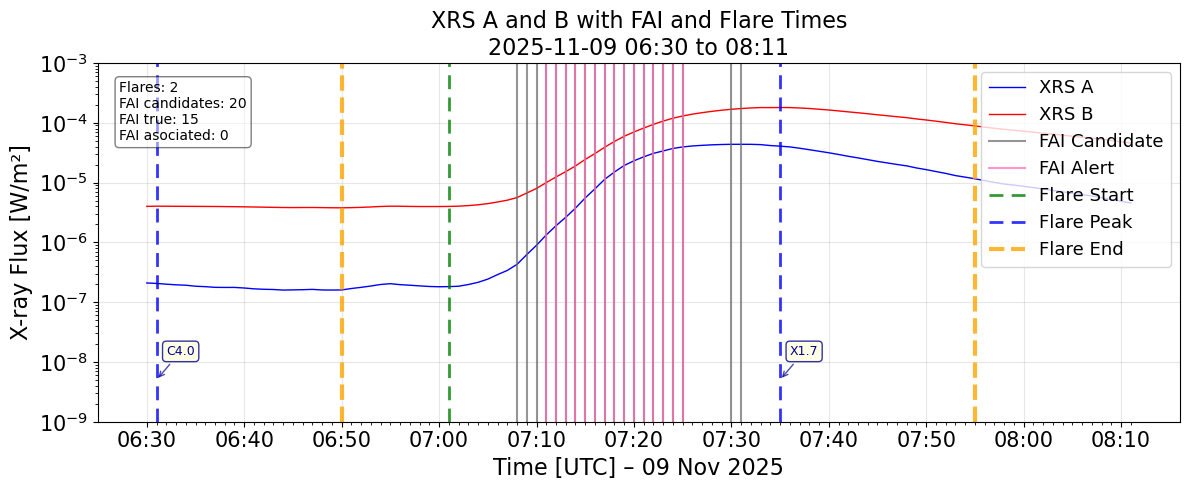

In [50]:
# 14 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all, 
                             df_flare_data=df_flares_all, # df_flares_valid no aparece X1.7 porque esta muy cerca del C4.0
                             flare_start_time="2025-11-09 06:30:00",
                             flare_end_time="2025-11-09 08:11:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='10min',
                             ymin=1e-9, ymax=1e-3,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

# debido a esta condición de clean_flares2.py
#min_gap_minutes=20    # Quitar solapamientos. tiempo entre el end y start del siguiente flare

Buscando datos entre: 2005-01-15 21:10:00 y 2005-01-15 23:37:00
Datos en df_plot: 148, FAI_assoc: 15, FAI_all: 30
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 30
FAI verdaderos en el intervalo: 15
FAI asociados a flares en el intervalo: 1


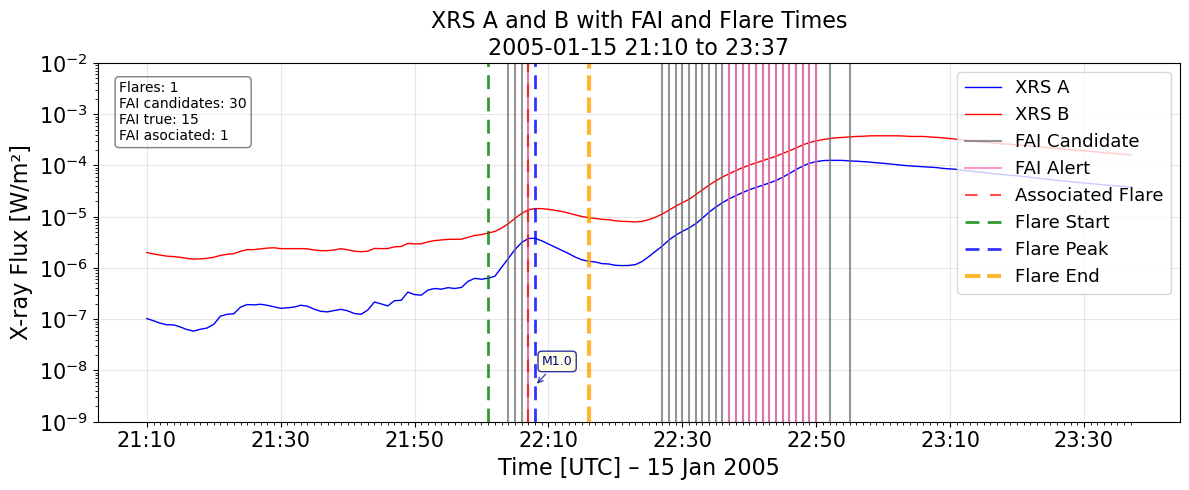

In [51]:
# 14 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2005-01-15 21:10:00",
                             flare_end_time="2005-01-15 23:37:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-9, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

#no aparece flare porque está muy cerca al M1.0

Buscando datos entre: 2011-09-24 08:38:00 y 2011-09-24 17:00:00
Datos en df_plot: 503, FAI_assoc: 19, FAI_all: 40
Fulguraciones en intervalo: 0
FAI candidatos en el intervalo: 40
FAI verdaderos en el intervalo: 19
FAI asociados a flares en el intervalo: 0


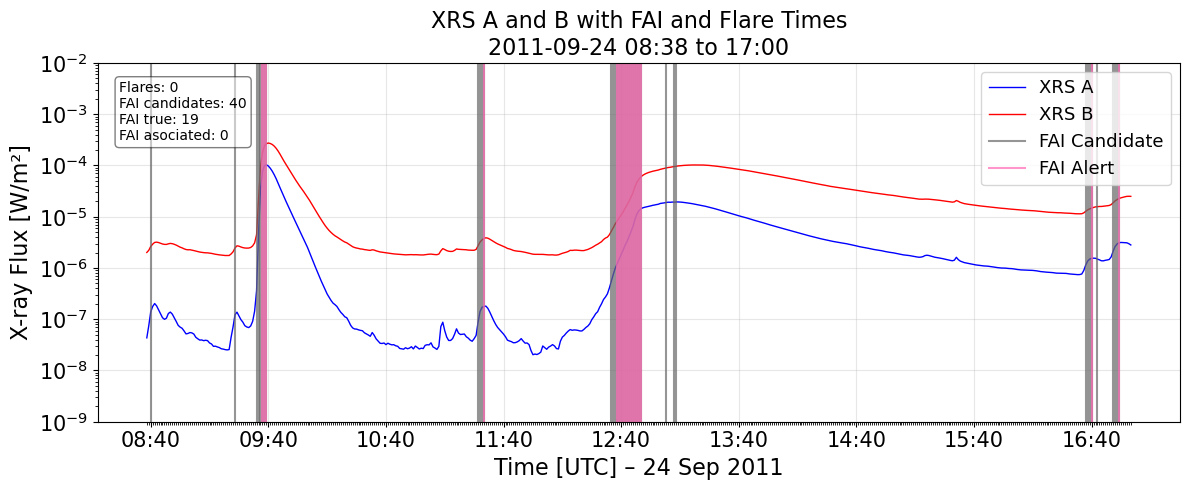

In [52]:
# 13 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2011-09-24 08:38:00",
                             flare_end_time="2011-09-24 17:00:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='60min',
                             ymin=1e-9, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

#no aparece flare en la DB pero en la pàgina si aparece reporte de 2 clase x: https://www.spaceweatherlive.com/en/archive/2011/09/24/xray.html


Buscando datos entre: 2005-05-13 15:36:00 y 2005-05-13 17:36:00
Datos en df_plot: 121, FAI_assoc: 13, FAI_all: 17
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 17
FAI verdaderos en el intervalo: 13
FAI asociados a flares en el intervalo: 0


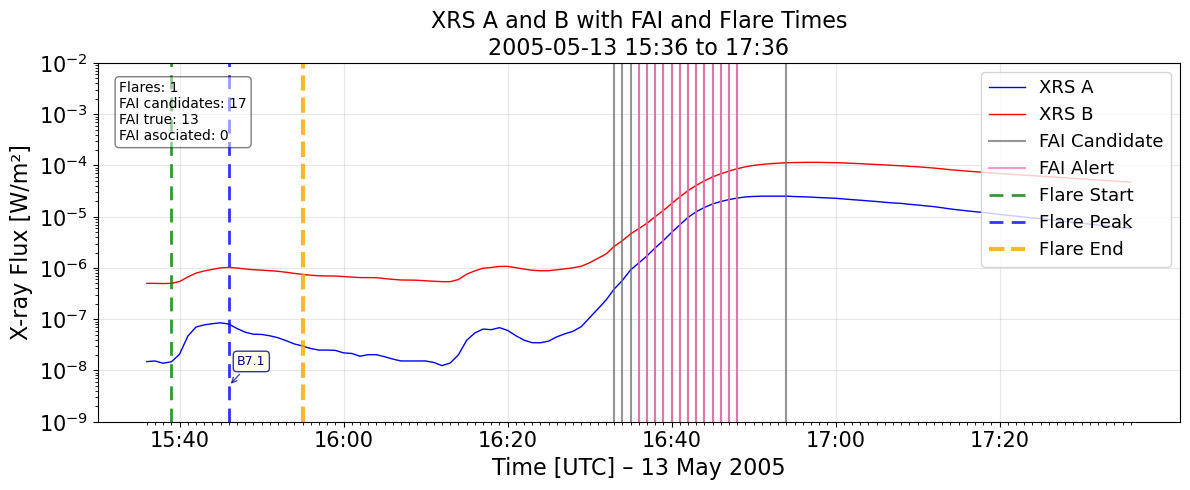

In [53]:
# 13 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2005-05-13 15:36:00",
                             flare_end_time="2005-05-13 17:36:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-9, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

#no aparece flare porque está muy cerca al B7.1

Buscando datos entre: 2011-09-25 02:35:00 y 2011-09-25 06:35:00
Datos en df_plot: 241, FAI_assoc: 12, FAI_all: 22
Fulguraciones en intervalo: 0
FAI candidatos en el intervalo: 22
FAI verdaderos en el intervalo: 12
FAI asociados a flares en el intervalo: 0


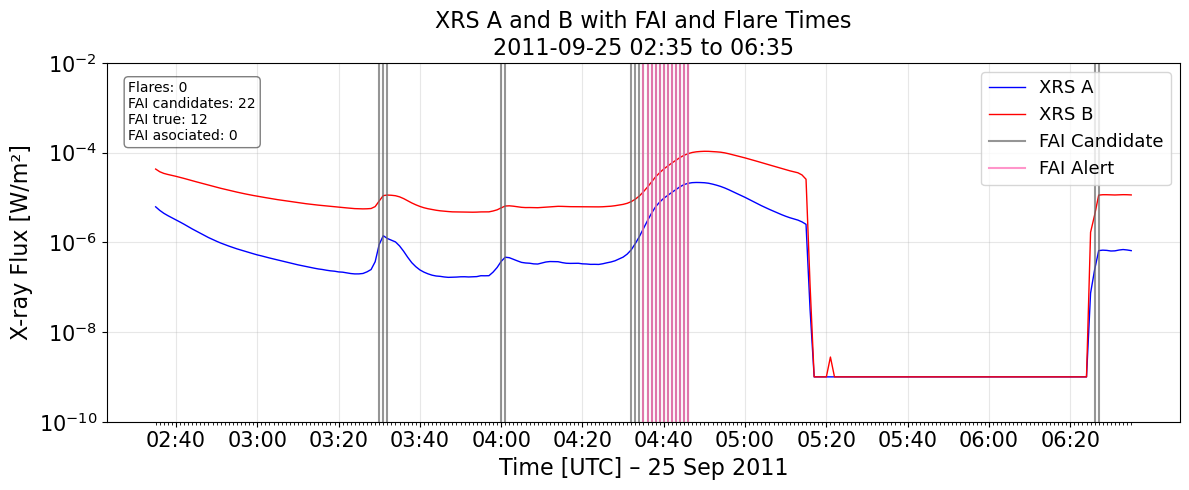

In [54]:
# 12 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2011-09-25 02:35:00",
                             flare_end_time="2011-09-25 06:35:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-10, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)


#no aparece flare en la DB pero en la pàgina si aparece reporte de un clase x: https://www.spaceweatherlive.com/en/archive/2011/09/25/xray.html

Buscando datos entre: 2002-04-21 00:00:00 y 2002-04-21 03:19:00
Datos en df_plot: 200, FAI_assoc: 19, FAI_all: 35
Fulguraciones en intervalo: 0
FAI candidatos en el intervalo: 35
FAI verdaderos en el intervalo: 19
FAI asociados a flares en el intervalo: 0


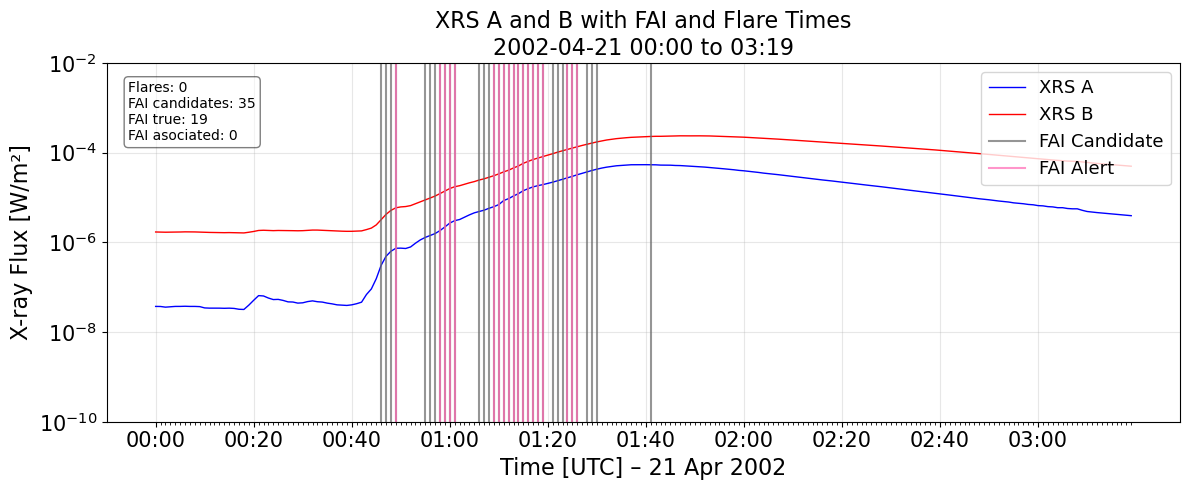

In [55]:
# 11 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_all,
                             flare_start_time="2002-04-21 00:00:00",
                             flare_end_time="2002-04-21 03:19:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-10, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

#no aparece flare en la DB pero en la pàgina si aparece reporte de un clase x: https://www.spaceweatherlive.com/en/archive/2002/04/21/xray.html

Buscando datos entre: 2024-01-29 03:15:00 y 2024-01-29 05:15:00
Datos en df_plot: 121, FAI_assoc: 11, FAI_all: 20
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 20
FAI verdaderos en el intervalo: 11
FAI asociados a flares en el intervalo: 0


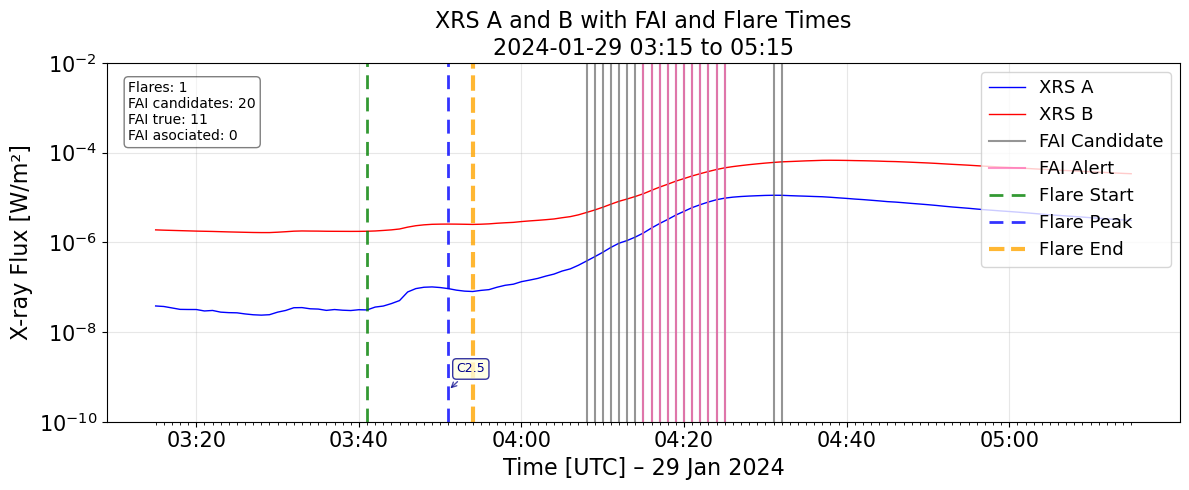

In [56]:
# 11 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2024-01-29 03:15:00",
                             flare_end_time="2024-01-29 05:15:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-10, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

#no aparece flare porque está muy cerca al C2.5

Buscando datos entre: 2025-01-21 09:19:00 y 2025-01-21 11:19:00
Datos en df_plot: 121, FAI_assoc: 10, FAI_all: 13
Fulguraciones en intervalo: 1
FAI candidatos en el intervalo: 13
FAI verdaderos en el intervalo: 10
FAI asociados a flares en el intervalo: 0


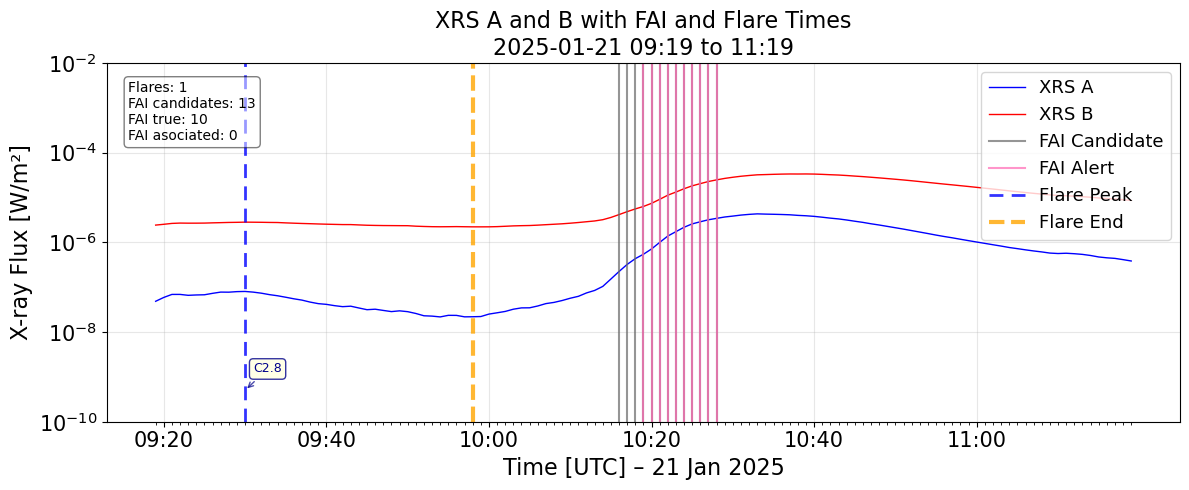

In [57]:
# 10 FAIs

plot_fai_and_flare_lines(df_combined=df_full,
                             df_fai_assoc=df_fai_assoc,
                             df_fai_all=df_fai_all,
                             df_flare_data=df_flares_valid,
                             flare_start_time="2025-01-21 09:19:00",
                             flare_end_time="2025-01-21 11:19:00", 
                             graphics_dir=FlarebyFlare_dir,
                             freq_ticks='20min',
                             ymin=1e-10, ymax=1e-2,
                             figsize=(12, 5),
                             save_plot=False,
                             annotate_counts=True)

#no aparece flare porque está muy cerca al C2.8

## buscar entre fechas

In [58]:
# Definir rango con horas, minutos y segundos
fecha_inicio = '2016-03-28 02:00:00'
fecha_fin    = '2016-03-28 03:00:00'

# Filtrar
df_filtrado_full_valid = df_full_valid[
    (df_full_valid['date'] >= fecha_inicio) & 
    (df_full_valid['date'] <= fecha_fin)
]

df_filtrado_full_valid

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing
1307828,2016-03-28 02:21:00,GOES-15,4.905031e-09,2.694281e-07,3.905031e-09,1.597703e-07,5.768917,2.403814e+47,5.012600,9.117961e+47,0.024038,0.091180,3,2016-03-28,False
1307829,2016-03-28 02:22:00,GOES-15,1.721039e-08,5.250917e-07,1.621039e-08,4.204823e-07,6.989125,4.047710e+47,6.079632,1.428854e+48,0.040477,0.142885,3,2016-03-28,False
1307830,2016-03-28 02:23:00,GOES-15,2.754204e-08,7.257552e-07,2.654204e-08,6.177715e-07,7.325886,5.408836e+47,6.381221,1.867502e+48,0.054088,0.186750,3,2016-03-28,False
1307831,2016-03-28 02:24:00,GOES-15,4.745159e-08,9.699723e-07,4.645159e-08,8.618200e-07,8.101265,6.273115e+47,7.082934,2.059041e+48,0.062731,0.205904,3,2016-03-28,False
1307832,2016-03-28 02:25:00,GOES-15,1.541586e-07,1.599528e-06,1.525682e-07,1.475711e-06,10.921687,7.021327e+47,9.786350,1.930651e+48,0.070213,0.193065,3,2016-03-28,False
1307833,2016-03-28 02:26:00,GOES-15,2.340616e-07,2.183639e-06,2.291566e-07,1.914211e-06,11.656815,8.480375e+47,10.570476,2.220201e+48,0.084804,0.222020,3,2016-03-28,False
1307834,2016-03-28 02:27:00,GOES-15,2.799820e-07,2.712248e-06,2.627716e-07,2.187157e-06,11.675064,9.673955e+47,10.590509,2.529526e+48,0.096740,0.252953,3,2016-03-28,False
1307835,2016-03-28 02:28:00,GOES-15,2.877012e-07,3.089645e-06,2.601591e-07,2.363889e-06,11.232262,1.089609e+48,10.112381,2.935344e+48,0.108961,0.293534,3,2016-03-28,False
1307836,2016-03-28 02:29:00,GOES-15,2.286264e-07,3.012556e-06,1.811748e-07,2.042584e-06,10.183761,1.058122e+48,9.040936,3.049936e+48,0.105812,0.304994,3,2016-03-28,False
1307837,2016-03-28 02:56:00,GOES-15,2.961602e-09,3.106328e-07,1.961602e-09,9.804765e-08,5.315664,1.838680e+47,4.632012,7.100049e+47,0.018387,0.071000,3,2016-03-28,False


In [59]:
# Definir rango con horas, minutos y segundos
fecha_inicio = '2016-03-28 02:00:00'
fecha_fin    = '2016-03-28 03:00:00'

# Filtrar
df_filtrado_fai_selected = df_fai_selected[
    (df_fai_selected['date'] >= fecha_inicio) & 
    (df_fai_selected['date'] <= fecha_fin)
]

df_filtrado_fai_selected

,date,observatory,xrsa,xrsb,xrsa_corr,xrsb_corr,T_cor,EM_cor,T_phot,EM_phot,EM_cor_norm,EM_phot_norm,month,day,GOES_missing,EM_diff,EM_jump,FAI_alert,FAI_true,delta_min,group_id,duration_from_start


In [60]:
# Definir rango con horas, minutos y segundos
fecha_inicio = '2016-03-28 02:10:00'
fecha_fin    = '2016-03-28 05:10:00'

# Filtrar
df_filtrado_anticipation_time = df_anticipation_time[
    (df_anticipation_time['StartTime'] >= fecha_inicio) & 
    (df_anticipation_time['StartTime'] <= fecha_fin)
]

print(df_filtrado_anticipation_time)

                Flare_ID           StartTime            PeakTime  \
36822  201603280228_C2.1 2016-03-28 02:18:00 2016-03-28 02:28:00   
36823  201603280259_B3.3 2016-03-28 02:54:00 2016-03-28 02:59:00   

                  EndTime  StartPeak  StartEnd  PeakEnd Class ClassLetter  \
36822 2016-03-28 02:32:00       10.0      14.0      4.0  C2.1           C   
36823 2016-03-28 03:04:00        5.0      10.0      5.0  B3.3           B   

       ClassNumber ClassGroup  NOAA_Class  PeakFlux Observatory Instrument  \
36822          2.1     C1-4.9         NaN       NaN        GOES       GOES   
36823          3.3     B1-4.9         NaN       NaN        GOES       GOES   

       NumSpots  NOAA_AR  Zurich  McIntosh  MtWilson  HPC_X       HPC_Y  \
36822       NaN  12524.0     NaN       NaN       NaN    0.0  113.057988   
36823       NaN  12526.0     NaN       NaN       NaN    0.0  113.037588   

       HGS_Long  HGS_Lat EventType  EventType2  FAIalerts_W  FAIalerts_WStart  \
36822       0.0      

In [61]:
df_anticipation_time.sort_values(by="FAIalerts_WStart", ascending=False)[6:10]

,Flare_ID,StartTime,PeakTime,EndTime,StartPeak,StartEnd,PeakEnd,Class,ClassLetter,ClassNumber,ClassGroup,NOAA_Class,PeakFlux,Observatory,Instrument,NumSpots,NOAA_AR,Zurich,McIntosh,MtWilson,HPC_X,HPC_Y,HGS_Long,HGS_Lat,EventType,EventType2,FAIalerts_W,FAIalerts_WStart,FAIalerts_WPeak,FAIalerts_StartPeak,FAIalerts_PeakEnd,FAIalerts_startEnd,AnticipationStart,AnticipationPeak,Peak_to_lastFAI,Time_since_prev_flare_end,Time_since_prev_flare_peak,RelAnticipation_Peak,RelAnticipation_Start
6678,198906202208_M9.3,1989-06-20 22:01:00,1989-06-20 22:08:00,1989-06-20 23:15:00,7.0,74.0,67.0,M9.3,M,9.3,M5-9.9,NaN,NaN,GOES,GOES,NaN,5528.0,NaN,NaN,NaN,887.0820,287.42820,81.0,18.0,FL,9,12,6,12,6,0,6,6.0,13.0,2.0,81.0,108.0,1.857143,0.857143
6946,198908301653_M7.1,1989-08-30 16:48:00,1989-08-30 16:53:00,1989-08-30 17:13:00,5.0,25.0,20.0,M7.1,M,7.1,M5-9.9,NaN,NaN,GOES,GOES,NaN,5669.0,NaN,NaN,NaN,-894.7800,-269.93160,-77.0,-15.0,FL,9,5,5,5,0,0,0,9.0,14.0,10.0,63.0,73.0,2.800000,1.800000
6445,198905121119_M1.2,1989-05-12 11:19:00,1989-05-12 11:19:00,1989-05-12 11:59:00,0.0,40.0,40.0,M1.2,M,1.2,M1-4.9,NaN,NaN,GOES,GOES,NaN,5476.0,NaN,NaN,NaN,312.1818,-421.81560,22.0,-29.0,FL,9,5,5,5,0,0,0,18.0,18.0,14.0,NaN,NaN,inf,inf
3198,198505130959_B4.0,1985-05-13 09:49:00,1985-05-13 09:59:00,1985-05-13 10:05:00,10.0,16.0,6.0,B4.0,B,4.0,B1-4.9,NaN,NaN,GOES,GOES,NaN,4652.0,NaN,NaN,NaN,0.0000,46.96434,0.0,0.0,FL,9,5,5,5,0,0,0,20.0,30.0,26.0,66.0,109.0,3.000000,2.000000


## Observatory

In [62]:
# Ver todos los observatorios únicos
print("Observatorios únicos:")
print(df_full_valid['observatory'].unique())

# O en formato de lista
print("\nLista de observatorios:")
print(list(df_full_valid['observatory'].unique()))

Observatorios únicos:
['GOES-2' 'GOES-5' 'GOES-6' 'GOES-7' 'GOES-9' 'GOES-8' 'GOES-10' 'GOES-12'
 'GOES-11' 'GOES-14' 'GOES-15' 'GOES-13' 'GOES-16' 'GOES-17' 'GOES-18']

Lista de observatorios:
['GOES-2', 'GOES-5', 'GOES-6', 'GOES-7', 'GOES-9', 'GOES-8', 'GOES-10', 'GOES-12', 'GOES-11', 'GOES-14', 'GOES-15', 'GOES-13', 'GOES-16', 'GOES-17', 'GOES-18']


In [63]:
# Ver observatorios con cantidad de registros
print("Conteo por observatorio:")
print(df_full_valid['observatory'].value_counts())

# Con porcentajes
print("\nPorcentajes por observatorio:")
print(df_full_valid['observatory'].value_counts(normalize=True) * 100)

Conteo por observatorio:
observatory
GOES-6     464943
GOES-15    285289
GOES-10    283224
GOES-18    219019
GOES-12    121313
GOES-2      56913
GOES-17     55223
GOES-5      34280
GOES-9      30840
GOES-7      24883
GOES-14     11283
GOES-16      9900
GOES-11      5595
GOES-13      1192
GOES-8         24
Name: count, dtype: int64

Porcentajes por observatorio:
observatory
GOES-6     28.987899
GOES-15    17.786973
GOES-10    17.658226
GOES-18    13.655224
GOES-12     7.563527
GOES-2      3.548367
GOES-17     3.443000
GOES-5      2.137262
GOES-9      1.922788
GOES-7      1.551386
GOES-14     0.703464
GOES-16     0.617237
GOES-11     0.348833
GOES-13     0.074318
GOES-8      0.001496
Name: proportion, dtype: float64


In [64]:
# Rango de fechas general
print("=== RANGOS DE FECHAS ===")
print(f"Fecha mínima: {df_full_valid['date'].min()}")
print(f"Fecha máxima: {df_full_valid['date'].max()}")

# Por observatorio
for observatorio in df_full_valid['observatory'].unique():
    subset = df_full_valid[df_full_valid['observatory'] == observatorio]
    print(f"\n{observatorio}:")
    print(f"  Desde: {subset['date'].min()}")
    print(f"  Hasta: {subset['date'].max()}")
    print(f"  Registros: {len(subset):,}")

=== RANGOS DE FECHAS ===
Fecha mínima: 1980-04-23 00:12:00
Fecha máxima: 2025-11-15 23:32:00

GOES-2:
  Desde: 1980-04-23 00:12:00
  Hasta: 1983-04-24 23:26:00
  Registros: 56,913

GOES-5:
  Desde: 1983-05-02 13:11:00
  Hasta: 1984-07-28 13:21:00
  Registros: 34,280

GOES-6:
  Desde: 1983-06-01 00:05:00
  Hasta: 1994-07-04 18:15:00
  Registros: 464,943

GOES-7:
  Desde: 1994-01-01 00:07:00
  Hasta: 1996-03-19 23:54:00
  Registros: 24,883

GOES-9:
  Desde: 1996-04-20 06:58:00
  Hasta: 1998-07-08 23:56:00
  Registros: 30,840

GOES-8:
  Desde: 1998-01-16 12:14:00
  Hasta: 1998-01-16 23:27:00
  Registros: 24

GOES-10:
  Desde: 1998-07-10 00:05:00
  Hasta: 2009-11-25 00:56:00
  Registros: 283,224

GOES-12:
  Desde: 2003-01-11 00:08:00
  Hasta: 2007-02-19 08:12:00
  Registros: 121,313

GOES-11:
  Desde: 2007-04-24 04:32:00
  Hasta: 2008-02-08 07:08:00
  Registros: 5,595

GOES-14:
  Desde: 2009-09-23 04:03:00
  Hasta: 2016-05-15 23:51:00
  Registros: 11,283

GOES-15:
  Desde: 2010-04-10 09:15

In [65]:
def diagnosticar_observatorios(df):
    """Función completa para diagnosticar los observatorios disponibles"""
    
    print("=== DIAGNÓSTICO DE OBSERVATORIOS ===")
    print(f"Total de registros: {len(df):,}")
    
    # Observatorios únicos
    observatorios = df['observatory'].unique()
    print(f"\n📡 Observatorios encontrados ({len(observatorios)}):")
    for i, obs in enumerate(observatorios, 1):
        print(f"  {i}. '{obs}'")
    
    # Conteo detallado
    print(f"\n📊 Conteo por observatorio:")
    conteo = df['observatory'].value_counts()
    for obs, count in conteo.items():
        porcentaje = (count / len(df)) * 100
        print(f"  '{obs}': {count:,} registros ({porcentaje:.1f}%)")
    
    # Rango de fechas por observatorio
    print(f"\n📅 Rango de fechas por observatorio:")
    for obs in observatorios:
        datos_obs = df[df['observatory'] == obs]
        fecha_min = datos_obs['date'].min()
        fecha_max = datos_obs['date'].max()
        print(f"  '{obs}': {fecha_min} a {fecha_max}")
    
    return observatorios



In [66]:
# Ejecutar el diagnóstico
observatorios_disponibles = diagnosticar_observatorios(df_full_valid)
observatorios_disponibles

=== DIAGNÓSTICO DE OBSERVATORIOS ===
Total de registros: 1,603,921

📡 Observatorios encontrados (15):
  1. 'GOES-2'
  2. 'GOES-5'
  3. 'GOES-6'
  4. 'GOES-7'
  5. 'GOES-9'
  6. 'GOES-8'
  7. 'GOES-10'
  8. 'GOES-12'
  9. 'GOES-11'
  10. 'GOES-14'
  11. 'GOES-15'
  12. 'GOES-13'
  13. 'GOES-16'
  14. 'GOES-17'
  15. 'GOES-18'

📊 Conteo por observatorio:
  'GOES-6': 464,943 registros (29.0%)
  'GOES-15': 285,289 registros (17.8%)
  'GOES-10': 283,224 registros (17.7%)
  'GOES-18': 219,019 registros (13.7%)
  'GOES-12': 121,313 registros (7.6%)
  'GOES-2': 56,913 registros (3.5%)
  'GOES-17': 55,223 registros (3.4%)
  'GOES-5': 34,280 registros (2.1%)
  'GOES-9': 30,840 registros (1.9%)
  'GOES-7': 24,883 registros (1.6%)
  'GOES-14': 11,283 registros (0.7%)
  'GOES-16': 9,900 registros (0.6%)
  'GOES-11': 5,595 registros (0.3%)
  'GOES-13': 1,192 registros (0.1%)
  'GOES-8': 24 registros (0.0%)

📅 Rango de fechas por observatorio:
  'GOES-2': 1980-04-23 00:12:00 a 1983-04-24 23:26:00
  '

array(['GOES-2', 'GOES-5', 'GOES-6', 'GOES-7', 'GOES-9', 'GOES-8',
       'GOES-10', 'GOES-12', 'GOES-11', 'GOES-14', 'GOES-15', 'GOES-13',
       'GOES-16', 'GOES-17', 'GOES-18'], dtype=object)

In [67]:
# Buscar observatorios que contengan "GOES"
print("Observatorios que contienen 'GOES':")
goes_observatories = [obs for obs in df_full_valid['observatory'].unique() if 'GOES' in obs.upper()]
print(goes_observatories)

# Buscar observatorios que contengan "16" (por si es GOES-16, GOES16, etc)
print("\nObservatorios que contienen '16':")
obs_16 = [obs for obs in df_full_valid['observatory'].unique() if '16' in obs]
print(obs_16)

Observatorios que contienen 'GOES':
['GOES-2', 'GOES-5', 'GOES-6', 'GOES-7', 'GOES-9', 'GOES-8', 'GOES-10', 'GOES-12', 'GOES-11', 'GOES-14', 'GOES-15', 'GOES-13', 'GOES-16', 'GOES-17', 'GOES-18']

Observatorios que contienen '16':
['GOES-16']


In [68]:
# Para un conteo rápido
observatorio = 'GOES-18'
inicio = pd.Timestamp('2025-08-28 14:00:00')
fin = pd.Timestamp('2025-08-28 16:00:00')

conteo = len(df_full_valid[
    (df_full_valid['observatory'] == observatorio) &
    (df_full_valid['date'] >= inicio) &
    (df_full_valid['date'] <= fin)
])

print(f"'{observatorio}' tiene {conteo} registros entre {inicio} y {fin}")

'GOES-18' tiene 41 registros entre 2025-08-28 14:00:00 y 2025-08-28 16:00:00


In [69]:
def contar_registros_observatorio(df, observatorio, fecha_inicio, fecha_fin):
    """
    Cuenta registros de un observatorio específico entre fechas dadas
    """
    # Aplicar filtros
    filtrado = df[
        (df['observatory'] == observatorio) &
        (df['date'] >= fecha_inicio) &
        (df['date'] <= fecha_fin)
    ]
    
    print(f"🔍 Observatorio: '{observatorio}'")
    print(f"📅 Rango: {fecha_inicio} a {fecha_fin}")
    print(f"📊 Registros encontrados: {len(filtrado):,}")
    
    if len(filtrado) > 0:
        print(f"📈 Primer registro: {filtrado['date'].min()}")
        print(f"📉 Último registro: {filtrado['date'].max()}")
        print(f"⏱️  Duración: {(filtrado['date'].max() - filtrado['date'].min())}")
    
    return len(filtrado)



In [70]:
# Ejemplo de uso
contar_registros_observatorio(
    df=df_full_valid,
    observatorio='GOES-16',  # Cambia por el observatorio que necesites
    fecha_inicio=pd.Timestamp('1980-01-05 00:13:00'),
    fecha_fin=pd.Timestamp('2016-01-01 00:00:00')
)

🔍 Observatorio: 'GOES-16'
📅 Rango: 1980-01-05 00:13:00 a 2016-01-01 00:00:00
📊 Registros encontrados: 0


0

In [71]:
def analizar_observatorio_rango(df, observatorio, fecha_inicio, fecha_fin):
    """
    Análisis detallado de un observatorio en un rango de fechas
    """
    print("=" * 60)
    print(f"ANÁLISIS DETALLADO - OBSERVATORIO: {observatorio}")
    print("=" * 60)
    
    # Aplicar filtros
    mascara = (
        (df['observatory'] == observatorio) &
        (df['date'] >= fecha_inicio) &
        (df['date'] <= fecha_fin)
    )
    
    datos_filtrados = df[mascara]
    total_registros = len(datos_filtrados)
    
    print(f"📅 Rango solicitado: {fecha_inicio} a {fecha_fin}")
    print(f"📊 Total de registros: {total_registros:,}")
    
    if total_registros == 0:
        print("❌ No se encontraron registros en este rango")
        return None
    
    # Información temporal
    print(f"\n📈 Primer registro: {datos_filtrados['date'].min()}")
    print(f"📉 Último registro: {datos_filtrados['date'].max()}")
    duracion = datos_filtrados['date'].max() - datos_filtrados['date'].min()
    print(f"⏱️  Duración total: {duracion}")
    
    # Análisis de datos faltantes
    print(f"\n🔍 Calidad de datos:")
    for col in ['T_cor', 'EM_cor', 'T_phot', 'EM_phot']:
        if col in df.columns:
            no_nulos = datos_filtrados[col].notna().sum()
            porcentaje = (no_nulos / total_registros) * 100
            print(f"   {col}: {no_nulos}/{total_registros} ({porcentaje:.1f}%) no nulos")
    
    # Estadísticas básicas
    print(f"\n📊 Estadísticas (datos no nulos):")
    for col in ['T_cor', 'EM_cor']:
        if col in df.columns and datos_filtrados[col].notna().sum() > 0:
            datos_validos = datos_filtrados[col].dropna()
            print(f"   {col}:")
            print(f"     Mín: {datos_validos.min():.2e}")
            print(f"     Máx: {datos_validos.max():.2e}")
            print(f"     Promedio: {datos_validos.mean():.2e}")
    
    return datos_filtrados



In [72]:
# Ejemplo de uso
analizar_observatorio_rango(
    df=df_full_valid,
    observatorio='GOES-16',
    fecha_inicio=pd.Timestamp('1980-01-05 00:13:00'),
    fecha_fin=pd.Timestamp('2016-01-01 00:00:00')
)

ANÁLISIS DETALLADO - OBSERVATORIO: GOES-16
📅 Rango solicitado: 1980-01-05 00:13:00 a 2016-01-01 00:00:00
📊 Total de registros: 0
❌ No se encontraron registros en este rango


In [73]:
def comparar_observatorios_rango(df, observatorios, fecha_inicio, fecha_fin):
    """
    Compara múltiples observatorios en el mismo rango de fechas
    """
    print("COMPARACIÓN DE OBSERVATORIOS")
    print(f"Rango: {fecha_inicio} a {fecha_fin}")
    print("-" * 50)
    
    resultados = {}
    
    for obs in observatorios:
        mascara = (
            (df['observatory'] == obs) &
            (df['date'] >= fecha_inicio) &
            (df['date'] <= fecha_fin)
        )
        
        datos_obs = df[mascara]
        total = len(datos_obs)
        
        resultados[obs] = {
            'registros': total,
            'datos': datos_obs
        }
        
        print(f"🔭 {obs}: {total:,} registros")
        
        if total > 0:
            # Calcular frecuencia aproximada (registros por hora)
            duracion_horas = (fecha_fin - fecha_inicio).total_seconds() / 3600
            freq_por_hora = total / duracion_horas if duracion_horas > 0 else 0
            print(f"   📏 Frecuencia: ~{freq_por_hora:.1f} registros/hora")
    
    return resultados


In [74]:

# Ejemplo con múltiples observatorios
observatorios_interes = ['GOES-16', 'GOES-10', 'GOES-12', 'GOES-11', 'GOES-14', 'GOES-15', 'GOES-13', 'GOES-18']  # Ajusta a los que tengas
resultados = comparar_observatorios_rango(
    df=df_full_valid,
    observatorios=observatorios_interes,
    fecha_inicio=pd.Timestamp('1980-01-05 00:13:00'),
    fecha_fin=pd.Timestamp('2001-02-15 21:01:00')
)

COMPARACIÓN DE OBSERVATORIOS
Rango: 1980-01-05 00:13:00 a 2001-02-15 21:01:00
--------------------------------------------------
🔭 GOES-16: 0 registros
🔭 GOES-10: 159,225 registros
   📏 Frecuencia: ~0.9 registros/hora
🔭 GOES-12: 0 registros
🔭 GOES-11: 0 registros
🔭 GOES-14: 0 registros
🔭 GOES-15: 0 registros
🔭 GOES-13: 0 registros
🔭 GOES-18: 0 registros
